# NIVEL 1: 'EDA' ESTRUCTURADO Y LIMPIEZA DE DATOS

## EJERCICIO 1: EXPLORACIÓN INICIAL DEL DATASET

#### OBJETIVOS:
Con "sprint8_complex.xlsx" responder a las preguntas:

- Cuantas filas y columnas tiene el dataset
- Tipos de datos tiene cada columna
- Hay duplicados?
- Datos coherentes a simple vista?
- Posibles problemas o inconvenientes evidentes

Para responderlas hay que:

- Analizar la dimension del dataset
- Monstrar una muestra representativa de filas
- Revisar los tipos de variables
- Detectar duplicados
- Coherencia de datos
- Identificar y describir posibles problemas iniciales (sin solucionarlos)


Primero de todo instalo openpyxl para poder abrir el archivo xlsx. Pandas tiene la función de abrir un arhivo xlsx, pero necesita las instrucciones de openyxl para hacerlo.

pip install openpyxl

Importación de librerias necesarias para el analisis, limpieza y gestión del dataset

In [1]:
import pandas as pd
import json
import seaborn as sns
import os
import matplotlib.pyplot as plt

In [2]:
dataset_s8 = pd.read_excel('sprint8_complex.xlsx')
dataset_s8.info()

<class 'pandas.DataFrame'>
RangeIndex: 1010 entries, 0 to 1009
Data columns (total 20 columns):
 #   Column                                    Non-Null Count  Dtype 
---  ------                                    --------------  ----- 
 0   Dades de l'enquesta de treballadors 2025  1008 non-null   object
 1   Unnamed: 1                                1007 non-null   str   
 2   Unnamed: 2                                1007 non-null   str   
 3   Unnamed: 3                                1007 non-null   str   
 4   Unnamed: 4                                1007 non-null   str   
 5   Unnamed: 5                                1007 non-null   str   
 6   Unnamed: 6                                1007 non-null   str   
 7   Unnamed: 7                                1007 non-null   str   
 8   Unnamed: 8                                1007 non-null   str   
 9   Unnamed: 9                                967 non-null    str   
 10  Unnamed: 10                               1007 non-null   s

### Muestra del dataset (20 primeros)

In [3]:
dataset_s8.head(20)


,Dades de l'enquesta de treballadors 2025,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19
0,Generades aleatòriament per seguretat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
3,0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23.0,3.0,1958.0,Dona,"1,469 â‚¬",True,NaN,Grup B,Cap de projecte,3.0,True,32108.0,25.0,10.1
4,1,Marc,MuÃ±oz,48840994W,Espanya,Alacant,8.0,11.0,1960.0,H,"2,718 â‚¬",NaN,True,Grup C,Senior analyst,0.0,True,19496.0,10.4,18.7
5,2,Noa,Serra,14308421X,Espanya,Alacant,27.0,4.0,1961.0,D,1358 euros,True,NaN,Grup A,TÃ¨cnic IT,4.0,NaN,NaN,NaN,16.7
6,3,Pol,Gil,58586340F,Espanya,Sevilla,13.0,10.0,1985.0,H,"1,478 â‚¬",True,NaN,Grup B,Data Analyst,2.0,False,NaN,NaN,18.3
7,4,David,Vila,82070937P,Espanya,Bilbao,29.0,11.0,1965.0,Dona,"1,284 â‚¬",NaN,True,Grup B,Administratiu,NaN,True,NaN,11.8,13.1
8,5,Alexia,Puig,25014631B,Espanya,Las Palmas de Gran Canaria,1.0,8.0,1978.0,D,"2,069 â‚¬",NaN,True,Grup B,Cap de projecte,0.0,NaN,NaN,NaN,19.9
9,6,David,GÃ³mez Vila,36998038E,Espanya,Palma,25.0,9.0,1971.0,D,"2,349 â‚¬",NaN,True,Grup B,Cap de projecte,NaN,True,6196.0,10.6,17.8


### Número de filas y columnas

In [4]:
print(f"Hay {dataset_s8.shape[0]} filas y {dataset_s8.shape[1]} columnas")

Hay 1010 filas y 20 columnas


### Tipo de datos y cantidad

In [5]:
dataset_s8.dtypes.value_counts()

str       17
object     3
Name: count, dtype: int64

Hay 17 columnas de tipo str y 3 tipo object

### Duplicados

El número de duplicados será 0 al tener en cuenta la primera columna. Se ha generado aleatoriamente un número, por lo que no contará como duplicado aún habiendo realmente duplicados.

In [6]:
dataset_s8.duplicated().sum()

np.int64(0)

En cambio, si quitamos la primera columna, si existen 6 filas repetidas. Por lo que aprovechamos para eliminarla, ya que funciona como un indice, pero ya hay un indice en la tabla.

In [7]:
dataset_s8.iloc[:,1:].duplicated().sum()

np.int64(6)

In [8]:
dataset_s8 = dataset_s8.drop(["Dades de l'enquesta de treballadors 2025"], axis=True)

In [9]:
dataset_s8.head(20)

,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
3,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23.0,3.0,1958.0,Dona,"1,469 â‚¬",True,NaN,Grup B,Cap de projecte,3.0,True,32108.0,25.0,10.1
4,Marc,MuÃ±oz,48840994W,Espanya,Alacant,8.0,11.0,1960.0,H,"2,718 â‚¬",NaN,True,Grup C,Senior analyst,0.0,True,19496.0,10.4,18.7
5,Noa,Serra,14308421X,Espanya,Alacant,27.0,4.0,1961.0,D,1358 euros,True,NaN,Grup A,TÃ¨cnic IT,4.0,NaN,NaN,NaN,16.7
6,Pol,Gil,58586340F,Espanya,Sevilla,13.0,10.0,1985.0,H,"1,478 â‚¬",True,NaN,Grup B,Data Analyst,2.0,False,NaN,NaN,18.3
7,David,Vila,82070937P,Espanya,Bilbao,29.0,11.0,1965.0,Dona,"1,284 â‚¬",NaN,True,Grup B,Administratiu,NaN,True,NaN,11.8,13.1
8,Alexia,Puig,25014631B,Espanya,Las Palmas de Gran Canaria,1.0,8.0,1978.0,D,"2,069 â‚¬",NaN,True,Grup B,Cap de projecte,0.0,NaN,NaN,NaN,19.9
9,David,GÃ³mez Vila,36998038E,Espanya,Palma,25.0,9.0,1971.0,D,"2,349 â‚¬",NaN,True,Grup B,Cap de projecte,NaN,True,6196.0,10.6,17.8


### Datos coherentes a simple vista?

Viendo la muestra, se detectan que hay columnas que se pueden juntar (Fills, No_Fills y Nombre_fills). Por el resto, está "bien" estructurado y solamente hay que pulir datos.

### Futuros problemas

Existen columnas que se pueden juntar (fills, no_fills y nombre_fills)
Codificación de las variables es erronea y las palabras con acentos o signos especiales se ven afectadas.
Estandarización: el salario mensual hay usuarios que lo han puesto en numeros y otros en texto. La columna "dona" deberia ser genero y las variables H/M, pero hay "Dona".
En varias columnas hay números decimales cuando podrían ser enteros (n hijos)

## EJERCICIO 2: VALIDACIÓN BÀSICA DE DATOS Y DECISIONES DE ELIMINACIÓN 

Aspectos a validar:

- ¿Existen identificadores únicos (DNI) para cada persona?
- ¿Qué vas a hacer con las filas duplicadas o registros repetidos?
- ¿Existen valores obligatorios que faltan o información incoherente?
- ¿Detectos formatos incorrectos, errores de codificación o valores imposibles?

Concretamente, tendrás que:

- Corregir posibles problemas de codificación y acentuación en los nombres de las columnas y en los valores de texto, si procede.
- Detectar y eliminar filas duplicadas exactas, indicando cuántos registros se han eliminado.
- Comprobar la unicidad del DNI. En caso de detectar DNIs duplicados, deberás analizar la coherencia de la información asociada y descartar o anular los registros que no sean fiables, justificando claramente la decisión tomada.
- Identificar los campos clave que no deberían contener valores nulos, detectar registros con información insuficiente y eliminar únicamente aquellas filas completamente vacías o con información irrecuperable o no sustituible, explicando por qué no es posible ni razonable imputarlas.

### DNI como identificadores

Para validar si existen DNIs y demás, es útil renombrar las columnas por su nombre correcto. En el dataframe se encuentran en la fila 3 (indice 2).

In [10]:
dataset_s8.columns = dataset_s8.iloc[2]
dataset_s8.head(10)

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
3,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23.0,3.0,1958.0,Dona,"1,469 â‚¬",True,NaN,Grup B,Cap de projecte,3.0,True,32108.0,25.0,10.1
4,Marc,MuÃ±oz,48840994W,Espanya,Alacant,8.0,11.0,1960.0,H,"2,718 â‚¬",NaN,True,Grup C,Senior analyst,0.0,True,19496.0,10.4,18.7
5,Noa,Serra,14308421X,Espanya,Alacant,27.0,4.0,1961.0,D,1358 euros,True,NaN,Grup A,TÃ¨cnic IT,4.0,NaN,NaN,NaN,16.7
6,Pol,Gil,58586340F,Espanya,Sevilla,13.0,10.0,1985.0,H,"1,478 â‚¬",True,NaN,Grup B,Data Analyst,2.0,False,NaN,NaN,18.3
7,David,Vila,82070937P,Espanya,Bilbao,29.0,11.0,1965.0,Dona,"1,284 â‚¬",NaN,True,Grup B,Administratiu,NaN,True,NaN,11.8,13.1
8,Alexia,Puig,25014631B,Espanya,Las Palmas de Gran Canaria,1.0,8.0,1978.0,D,"2,069 â‚¬",NaN,True,Grup B,Cap de projecte,0.0,NaN,NaN,NaN,19.9
9,David,GÃ³mez Vila,36998038E,Espanya,Palma,25.0,9.0,1971.0,D,"2,349 â‚¬",NaN,True,Grup B,Cap de projecte,NaN,True,6196.0,10.6,17.8


Borro las 3 primeras filas porque no tienen datos

In [11]:
dataset_s8 = dataset_s8.drop(dataset_s8.index[0:3])
dataset_s8.head(10)

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
3,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23.0,3.0,1958.0,Dona,"1,469 â‚¬",True,NaN,Grup B,Cap de projecte,3.0,True,32108.0,25.0,10.1
4,Marc,MuÃ±oz,48840994W,Espanya,Alacant,8.0,11.0,1960.0,H,"2,718 â‚¬",NaN,True,Grup C,Senior analyst,0.0,True,19496.0,10.4,18.7
5,Noa,Serra,14308421X,Espanya,Alacant,27.0,4.0,1961.0,D,1358 euros,True,NaN,Grup A,TÃ¨cnic IT,4.0,NaN,NaN,NaN,16.7
6,Pol,Gil,58586340F,Espanya,Sevilla,13.0,10.0,1985.0,H,"1,478 â‚¬",True,NaN,Grup B,Data Analyst,2.0,False,NaN,NaN,18.3
7,David,Vila,82070937P,Espanya,Bilbao,29.0,11.0,1965.0,Dona,"1,284 â‚¬",NaN,True,Grup B,Administratiu,NaN,True,NaN,11.8,13.1
8,Alexia,Puig,25014631B,Espanya,Las Palmas de Gran Canaria,1.0,8.0,1978.0,D,"2,069 â‚¬",NaN,True,Grup B,Cap de projecte,0.0,NaN,NaN,NaN,19.9
9,David,GÃ³mez Vila,36998038E,Espanya,Palma,25.0,9.0,1971.0,D,"2,349 â‚¬",NaN,True,Grup B,Cap de projecte,NaN,True,6196.0,10.6,17.8
10,Carmen,LÃ³pez,47376585K,Espanya,Barcelona,8.0,9.0,1962.0,H,"2,855 â‚¬",True,NaN,Grup C,Responsable de vendes,4.0,True,20000,5.9,15.4
11,Nora,Andersen Pedersen,37289414J,Noruega,Stavanger,8.0,3.0,1963.0,D,"1,338 â‚¬",NaN,True,Grup B,Analista junior,0.0,False,NaN,NaN,7.6
12,Alba,GarcÃ­a,75181648S,Espanya,Las Palmas de Gran Canaria,32.0,0.0,1940.0,H,"1,450 â‚¬",True,NaN,Grup A,Senior analyst,4.0,False,NaN,NaN,20.1


Si existen DNIs como identificadores. Ahora compruebo si son únicos o repetidos y los muestro. 

In [12]:
dni_duplicado = dataset_s8[dataset_s8.duplicated(['DNI'])]
dni_duplicado.sort_values(by='DNI')

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
607,Laia,Navarro,15909601K,Espanya,Bilbao,30.0,5.0,1958.0,D,"1,676 â‚¬",True,False,Grup A,Analista,1,True,50.0,NaN,14.2
757,Oriol,GÃ³mez,16618423V,Espanya,Barcelona,10.0,1.0,1968.0,Home,2.358 â‚¬,True,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN
761,Oriol,GÃ³mez,16618423V,Espanya,MÃ laga,10.0,1.0,1968.0,H,1879 euros,True,NaN,Grup B,Data Analyst,4.0,False,NaN,NaN,NaN
762,Oriol,GÃ³mez,16618423V,Espanya,Sevilla,10.0,1.0,1968.0,NaN,"2,000 â‚¬",NaN,NaN,Grup A,Responsable de vendes,5.0,NaN,NaN,NaN,20.7
695,Alexia,PÃ©rez DÃ­az,49529438G,Espanya,MÃ laga,12.0,10.0,1981.0,Dona,1663â‚¬,NaN,True,Grup C,Cap de projecte,NaN,True,80000,10.7,16.9
1007,Oriol,Ferrer,52590001R,Espanya,Zaragoza,15.0,7.0,1973.0,D,786â‚¬,NaN,True,Grup A,Analista,0.0,True,81381.0,6.5,13.9
145,Marta,Ruiz,54013571W,Espanya,Palma,24.0,5.0,1982.0,H,"1,276 â‚¬",True,True,Grup A,Analista,0.0,False,NaN,NaN,15.7
43,Ida,Karlsen Eriksen,55283701C,Noruega,Oslo,2.0,9.0,1992.0,D,"1,614 â‚¬",True,NaN,Grup B,Analista,3.0,NaN,NaN,NaN,10.6
1006,Claudia,Gil Ferrer,55297384F,Espanya,ValÃ¨ncia,1.0,11.0,1981.0,H,1.789 â‚¬,NaN,True,Grup B,Responsable de vendes,0.0,True,29952.0,9.2,20.3
107,Oriol,Vila Casals,90585882A,Espanya,Madrid,30.0,9.0,1964.0,H,1987 euros,NaN,True,Grup B,Responsable de vendes,0.0,False,NaN,NaN,13.5


Existen varios DNIs repetidos. En algunos casos solo 2 veces (los que se ven solo una vez en la tabla de arriba), pero otros tienen varias repeticiones y con distinto nombre de usuario.

La eliminación de los DNis repetidos lo haré en el siguiente paso. También los DNIs nulos

### Registros duplicados y repetidos

Primero, corrijo la codificación por si existen registros duplicados, pero que tengan elementos bien codificados y otros mal. Si existiesen ese tipo de casos, no contarían como duplicados. Se aplica una corrección a todas las columnas.

Se crea una función para obtener un valor. Si el valor no es str lo devuelve.

Mientras hayan correcciones en valor (todo el codigo dentro de While) seguirá funcionando. Cuando no haya más cambios, parará (corregido = True/False)

Se han intrucido cp1252 y latin1 por si alguno no corrige correctamente el valor.

Se le agrega un replace para quitar los "_" de los titulos de las columnas.

Ejecuto un apply para que recorra las columnas y aplique con map la funcion a cada valor.

Solamente haciendo el cp1252 dejaba algún elemento sin corregir.

In [13]:
def corregir_texto(valor):
    if not isinstance(valor, str):
        return valor

    while True:
        corregido = False

        for encoding in ('cp1252', 'latin1'):
            try:
                nuevo = valor.encode(encoding).decode('utf-8')

                if nuevo != valor:
                    valor = nuevo
                    corregido = True
                    break

            except (UnicodeEncodeError, UnicodeDecodeError):
                pass

        if not corregido:
            break

    return valor.replace("_", ' ')

dataset_s8 = dataset_s8.apply(lambda col: col.map(corregir_texto))
dataset_s8.sample(10)

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
369,Chiara,Rossi Marino,60858151C,Itàlia,Torino,5.0,11.0,1959.0,M,821 €,True,NaN,Grup A,Analista junior,3.0,NaN,NaN,NaN,42.0
1003,Sara,Serra,90585882A,Espanya,Tarragona,28.0,5.0,2002.0,D,"1,073 €",NaN,True,Grup A,Administratiu,0.0,False,NaN,NaN,15.8
281,Víctor,García,89551741H,Espanya,València,15.0,12.0,1973.0,F,"1,778 €",True,NaN,Grup B,Administratiu,2.0,NaN,NaN,NaN,16.6
756,Aina,Ribera,43716263M,Espanya,València,9.0,6.0,1979.0,D,"1,636 €",NaN,True,Grup B,Tècnic IT,NaN,True,80000,13.3,NaN
757,Oriol,Gómez,16618423V,Espanya,Barcelona,10.0,1.0,1968.0,Home,2.358 €,True,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN
391,Carlos,Ruiz,36512868F,Espanya,Alacant,6.0,5.0,1987.0,D,"1,556 €",NaN,True,Grup B,Tècnic IT,0.0,False,NaN,NaN,17.3
98,Elena,Moretti,19031632A,Itàlia,Roma,7.0,4.0,1959.0,NC,2488 euros,True,NaN,Grup C,Analista,1.0,True,42398.0,25.0,19.2
844,Élise,Robert,54519864D,França,Lille,9.0,9.0,1969.0,H,"2,225 €",True,True,Grup C,Analista,0.0,True,80000,12.4,12.0
295,Sergio,López,64956876C,Espanya,Las Palmas de Gran Canaria,1.0,2.0,1982.0,H,3001€,NaN,True,Grup C,Cap de projecte,0.0,False,NaN,NaN,24.4
521,Laia,Gómez García,46568726A,Espanya,Palma,2.0,4.0,2002.0,D,958 euros,NaN,NaN,Grup A,Tècnic IT,0.0,NaN,NaN,NaN,19.8


Como la codificación se ha hecho después de definir el nombre de las columnas, "Càrrec" está mal escrita por lo que se lanza la función que se ha hecho antes a las columnas

In [14]:
dataset_s8.columns = dataset_s8.columns.map(corregir_texto)
dataset_s8.sample(10)

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Te cotxe,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat
863,Thomas,David,27341287F,França,Bordeaux,8.0,6.0,1972.0,Dona,n/d,True,NaN,Grup A,Tècnic IT,1.0,False,NaN,NaN,16.2
894,Hugo,Pérez Muñoz,48364464A,Espanya,Tarragona,19.0,3.0,1968.0,H,"1,283 €",True,NaN,Grup A,Analista junior,1,NaN,NaN,NaN,16.8
598,Paolo,Gallo De Luca,21034254X,Itàlia,Firenze,19.0,10.0,1976.0,H,"2,254 €",True,True,Grup C,Senior analyst,0,True,67158.0,13.2,14.1
448,Davide,Ferrari,93297363C,Itàlia,Firenze,2.0,11.0,1974.0,D,1435 euros,True,NaN,Grup B,Analista,1.0,True,44565.0,6.1,16.1
885,Jordi,Ruiz Romero,26489417K,Espanya,Sevilla,23.0,12.0,1962.0,H,932 €,NaN,True,Grup A,Tècnic IT,NaN,False,NaN,NaN,24.8
173,Nil,Ribera,55748676B,Espanya,Valladolid,31.0,8.0,2000.0,D,"1,156 €",NaN,True,Grup A,Analista,NaN,False,NaN,NaN,12.9
855,Pau,Romero Hernández,59652384T,Espanya,Tarragona,10.0,6.0,1969.0,H,1.276 €,True,NaN,Grup A,Analista,1.0,True,113111.0,25.0,15.7
507,Emil,Hansen,16003970L,Noruega,Trondheim,23.0,9.0,1980.0,H,"1,015 €",NaN,True,Grup A,Senior analyst,0.0,NaN,NaN,NaN,3.9
72,Laura,Hoffmann Bauer,61894582X,Alemanya,Berlin,15.0,12.0,1983.0,D,1.798 €,NaN,True,Grup B,Data Analyst,0.0,True,113964.0,7.0,11.1
927,Sara,García,86887786C,Espanya,Màlaga,30.0,11.0,1997.0,Home,"2,502 €",True,NaN,Grup C,Data Analyst,2.0,False,NaN,NaN,19.7


Ahora compruebo los registros duplicados y los borro. 

In [15]:
registros_duplicados = dataset_s8[dataset_s8.duplicated()]
registros_duplicados

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Te cotxe,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat
43,Ida,Karlsen Eriksen,55283701C,Noruega,Oslo,2.0,9.0,1992.0,D,"1,614 €",True,NaN,Grup B,Analista,3.0,NaN,NaN,NaN,10.6
1005,Alba,Muñoz,97954019T,Espanya,Bilbao,25.0,10.0,1983.0,D,"1,409 €",NaN,True,Grup B,Responsable de vendes,0.0,NaN,NaN,NaN,14.7
1006,Claudia,Gil Ferrer,55297384F,Espanya,València,1.0,11.0,1981.0,H,1.789 €,NaN,True,Grup B,Responsable de vendes,0.0,True,29952.0,9.2,20.3
1007,Oriol,Ferrer,52590001R,Espanya,Zaragoza,15.0,7.0,1973.0,D,786€,NaN,True,Grup A,Analista,0.0,True,81381.0,6.5,13.9


Borramos los 4 registros duplicados.
Volvemos a comprobar los duplicados y ya no hay.

In [16]:
dataset_s8 = dataset_s8.drop_duplicates()
registros_duplicados = dataset_s8[dataset_s8.duplicated()]
registros_duplicados


2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Te cotxe,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat


Tomaré la columna DNI como dato identificador y único de los usuarios. Como se ha comprobado antes, existen DNIs repetidos. Antes de borrarlos, compruebo si hay DNI con mayusculas/minusculas, con espacios y guiones. De esta manera nos aseguramos borrar los adecuados.

In [17]:
dni_espacio = dataset_s8[dataset_s8['DNI'].str.contains(' ')]
dni_espacio

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Te cotxe,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat


In [18]:
dni_guion = dataset_s8[dataset_s8['DNI'].str.contains('-')]
dni_guion

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Te cotxe,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat


No hay DNIs con espacios ni con guiones, por lo que omito la acción de borrarlos DNIs.

Ahora pongo todas las letras de los DNIs en mayuscula y elimino los duplicados.

In [19]:
dataset_s8['DNI'] = dataset_s8['DNI'].str.upper()
dni_num_duplicados = dataset_s8.duplicated(subset=['DNI']).sum()
print(f"Se han eliminado {dni_num_duplicados} DNIs duplicados")
dataset_s8 = dataset_s8.drop_duplicates(subset=['DNI'])
dataset_s8.head(10)

Se han eliminado 11 DNIs duplicados


2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Te cotxe,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat
3,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23.0,3.0,1958.0,Dona,"1,469 €",True,NaN,Grup B,Cap de projecte,3.0,True,32108.0,25.0,10.1
4,Marc,Muñoz,48840994W,Espanya,Alacant,8.0,11.0,1960.0,H,"2,718 €",NaN,True,Grup C,Senior analyst,0.0,True,19496.0,10.4,18.7
5,Noa,Serra,14308421X,Espanya,Alacant,27.0,4.0,1961.0,D,1358 euros,True,NaN,Grup A,Tècnic IT,4.0,NaN,NaN,NaN,16.7
6,Pol,Gil,58586340F,Espanya,Sevilla,13.0,10.0,1985.0,H,"1,478 €",True,NaN,Grup B,Data Analyst,2.0,False,NaN,NaN,18.3
7,David,Vila,82070937P,Espanya,Bilbao,29.0,11.0,1965.0,Dona,"1,284 €",NaN,True,Grup B,Administratiu,NaN,True,NaN,11.8,13.1
8,Alexia,Puig,25014631B,Espanya,Las Palmas de Gran Canaria,1.0,8.0,1978.0,D,"2,069 €",NaN,True,Grup B,Cap de projecte,0.0,NaN,NaN,NaN,19.9
9,David,Gómez Vila,36998038E,Espanya,Palma,25.0,9.0,1971.0,D,"2,349 €",NaN,True,Grup B,Cap de projecte,NaN,True,6196.0,10.6,17.8
10,Carmen,López,47376585K,Espanya,Barcelona,8.0,9.0,1962.0,H,"2,855 €",True,NaN,Grup C,Responsable de vendes,4.0,True,20000,5.9,15.4
11,Nora,Andersen Pedersen,37289414J,Noruega,Stavanger,8.0,3.0,1963.0,D,"1,338 €",NaN,True,Grup B,Analista junior,0.0,False,NaN,NaN,7.6
12,Alba,García,75181648S,Espanya,Las Palmas de Gran Canaria,32.0,0.0,1940.0,H,"1,450 €",True,NaN,Grup A,Senior analyst,4.0,False,NaN,NaN,20.1


Borrados los DNI duplicados, compruebo la longitud de estos. Un DNI español tiene 9 caracteres. En caso de que sean extranjeros con un NIE también son 9 caracteres.

Primero cuento los DNIs que no tienen esa longitud

In [20]:
dni_longitud_mal = dataset_s8[dataset_s8['DNI'].str.len() != 9]
dni_longitud_mal

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Te cotxe,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat
1008,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1009,???,###,XXXX,Narnia,Desconeguda,-99.0,99.0,3000.0,??,molts,NaN,NaN,Z,???,NaN,NaN,NaN,NaN,NaN


Sabiendo que hay 2 filas con DNIs con una longitud diferente a 9. Los borro

In [21]:
def longitud_dni(valor):
    return isinstance(valor, str) and len(valor) == 9

dataset_s8 = dataset_s8[dataset_s8['DNI'].apply(longitud_dni)]
dataset_s8.sample(10)

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Te cotxe,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat
49,Joana,Gil Ferrer,75679047L,Espanya,Girona,4.0,11.0,1984.0,D,2130€,True,NaN,Grup C,Tècnic IT,4.0,False,NaN,NaN,13.1
630,Arthur,Bertrand Leroy,18426588S,França,Nantes,2.0,2.0,1968.0,H,824€,True,True,Grup A,Administratiu,0,NaN,NaN,NaN,13.9
920,Claudia,Gil Fernández,19213734E,Espanya,Palma,3.0,7.0,1971.0,M,n/d,NaN,True,Grup C,Senior analyst,NaN,True,81219.0,6.6,13.3
105,Noa,Ruiz Pérez,18113477L,Espanya,Murcia,12.0,8.0,1990.0,NaN,"2,627 €",True,NaN,Grup D,Responsable de vendes,1.0,False,NaN,NaN,22.2
250,Nicolas,David,71823092V,França,Nantes,21.0,3.0,1988.0,H,"1,666 €",NaN,True,Grup B,Administratiu,NaN,True,NaN,NaN,13.1
667,Aina,Costa Sánchez,35357498P,Espanya,València,0.0,0.0,3000.0,D,1156 euros,NaN,True,Grup A,Responsable de vendes,NaN,True,65950,0.5,18.0
64,Xavier,Muñoz Roca,21370793D,Espanya,València,20.0,3.0,1983.0,NaN,3016€,NaN,True,Grup D,Tècnic IT,0.0,False,NaN,NaN,15.1
489,Alba,Roca,78045733K,Espanya,Alacant,-5.0,99.0,1940.0,Dona,"1,336 €",NaN,NaN,Grup A,Cap de projecte,NaN,True,12431.0,0.5,17.2
333,Núria,Costa,20498581L,Espanya,Valladolid,6.0,4.0,1969.0,NC,"1,577 €",True,True,Grup B,Cap de projecte,1.0,NaN,NaN,NaN,11.7
827,Alba,Roca Ramos,53919906E,Espanya,Girona,23.0,9.0,1977.0,F,"1,640 €",True,NaN,Grup B,Cap de projecte,1,False,NaN,NaN,16.3


### Valores nulos

Ante la existencia de los valores nulos, borro las filas que tengan TODAS las columnas con nulos. En este caso solo 1 fila tiene todo nulos.

In [22]:
num_nulos = dataset_s8.isna().all(axis=1).sum()
nulos = dataset_s8.isna().all(axis=1)
dataset_s8 = dataset_s8.dropna(how="all")
print(nulos)
num_nulos

3       False
4       False
5       False
6       False
7       False
        ...  
999     False
1000    False
1001    False
1002    False
1004    False
Length: 990, dtype: bool


np.int64(0)

También compruebo si en DNI hay nulos. En este caso no hay.

In [23]:
dni_nulos = dataset_s8[dataset_s8['DNI'].isna()]
dni_nulos


2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Te cotxe,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat


### Formatos incorrectos

In [24]:
dataset_s8.sample(10)

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Te cotxe,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat
829,Mia,Wolf,44364245Q,Alemanya,Hamburg,15.0,6.0,2004.0,F,"1,441 €",True,NaN,Grup A,Senior analyst,3.0,False,NaN,NaN,6.4
911,David,Fernández,99490648V,Espanya,A Coruña,10.0,8.0,1979.0,H,2056 euros,NaN,True,Grup B,Senior analyst,0.0,False,NaN,NaN,15.1
436,Anna,Sánchez,57957055W,Espanya,Murcia,32.0,0.0,1940.0,D,1078€,True,NaN,Grup A,Administratiu,1,True,80000,7.4,18.8
851,Víctor,Romero,53025024P,Espanya,Sevilla,18.0,11.0,1979.0,M,3425 euros,True,NaN,Grup D,Data Analyst,4.0,NaN,NaN,NaN,42.0
696,Lucía,Sánchez,78555677A,Espanya,Bilbao,15.0,9.0,1990.0,A,"2,947 €",True,NaN,Grup D,Responsable de vendes,2.0,True,18402.0,NaN,15.5
866,Paolo,Barbieri Romano,60603699M,Itàlia,Firenze,2.0,7.0,1980.0,M,"1,804 €",NaN,True,Grup C,Administratiu,NaN,True,6369.0,0.5,11.3
972,Marta,Vila,69389198K,Espanya,Las Palmas de Gran Canaria,13.0,1.0,1988.0,M,"2,403 €",NaN,True,Grup C,Administratiu,NaN,True,7861.0,NaN,19.3
78,Adrià,Ramos,50818905M,Espanya,València,5.0,9.0,1965.0,D,"1,156 €",NaN,True,Grup A,Data Analyst,NaN,False,NaN,NaN,NaN
599,Marc,Costa,35801896J,Espanya,Barcelona,19.0,9.0,1993.0,D,1900€,NaN,True,Grup B,Data Analyst,NaN,NaN,NaN,NaN,20.8
334,Guillem,Ferrer,63015631D,Espanya,Murcia,12.0,10.0,1997.0,H,1880 euros,NaN,True,Grup C,Analista junior,0.0,True,54025.0,25.0,20.3


Corregido la codificación con el "cp1252" y "latin1", el formato que falla es el número de hijos, dia, mes y año de nacimiento. Estos parámetros deberían ser números enteros y no decimales (aunque realmente es un texto).

A continuación, busco todos los valores únicos de cada categoria para buscar valores imposibles, si son todos "decimales" u otra opción.

In [25]:
dataset_s8['Nombre fills'].unique()

array(['3.0', '0.0', '4.0', '2.0', nan, '1.0', 0, 1], dtype=object)

In [26]:
dataset_s8['Dia de Naixement'].unique()

<StringArray>
['23.0',  '8.0', '27.0', '13.0', '29.0',  '1.0', '25.0', '32.0', '24.0',
 '22.0', '10.0', '21.0', '14.0', '19.0', '15.0', '16.0', '11.0', '18.0',
 '28.0',  '9.0',  '3.0',  '2.0',  '0.0', '20.0',  '4.0', '-5.0', '26.0',
 '30.0', '17.0',  '5.0', '12.0',  '6.0',  '7.0', '31.0']
Length: 34, dtype: str

In [27]:
dataset_s8['Mes de Naixement'].unique()

<StringArray>
[ '3.0', '11.0',  '4.0', '10.0',  '8.0',  '9.0',  '0.0',  '6.0',  '2.0',
  '7.0',  '5.0', '12.0',  '1.0', '99.0', '13.0']
Length: 15, dtype: str

In [28]:
dataset_s8['Any de Naixement'].unique()

<StringArray>
['1958.0', '1960.0', '1961.0', '1985.0', '1965.0', '1978.0', '1971.0',
 '1962.0', '1963.0', '1940.0', '1974.0', '1973.0', '1980.0', '2004.0',
 '1964.0', '2002.0', '1993.0', '1972.0', '1982.0', '1987.0', '1992.0',
 '1994.0', '1967.0', '1990.0', '3000.0', '2019.0', '1976.0', '2001.0',
 '1997.0', '1984.0', '1977.0', '1988.0', '1995.0', '1981.0', '1983.0',
 '2003.0', '1991.0', '2000.0', '1989.0', '2026.0', '1966.0', '1959.0',
 '1969.0', '1975.0', '1986.0', '1999.0', '1979.0', '1996.0', '1998.0',
 '1970.0', '1968.0']
Length: 51, dtype: str

También las columnas Fills, No Fills y Te_cotxe deberian ser boleanas. Incluso Gènere si consideramos que solamente hay 2 generos. Fills y No Fills se fusionarán con Nombre fills y Te cotxe se modificará en el ejercicio 3.

Visto los datos únicos de cada columna se procede a cambiarlos de formato. Primero a float al tener escritura con decimales y despues a int64 (evita errores si hay nulos). Modifico las 4 columnas

In [29]:
columnas = ['Dia de Naixement', 'Mes de Naixement', 'Any de Naixement', 'Nombre fills']
dataset_s8[columnas] = dataset_s8[columnas].astype(float).astype('Int64')
print(dataset_s8['Dia de Naixement'].unique())
dataset_s8.info()

<IntegerArray>
[23,  8, 27, 13, 29,  1, 25, 32, 24, 22, 10, 21, 14, 19, 15, 16, 11, 18, 28,
  9,  3,  2,  0, 20,  4, -5, 26, 30, 17,  5, 12,  6,  7, 31]
Length: 34, dtype: Int64
<class 'pandas.DataFrame'>
Index: 990 entries, 3 to 1004
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Nom                         990 non-null    str   
 1   Cognoms                     990 non-null    str   
 2   DNI                         990 non-null    str   
 3   País d'origen               990 non-null    str   
 4   Ciutat                      990 non-null    str   
 5   Dia de Naixement            990 non-null    Int64 
 6   Mes de Naixement            990 non-null    Int64 
 7   Any de Naixement            990 non-null    Int64 
 8   Gènere                      951 non-null    str   
 9   Salari mensual              990 non-null    str   
 10  Fills                       414 non-null    str   
 11 

El siguiente paso es crear columna de fecha. Hay que unificarlas en una misma columna.

Pandas tiene una función de convertir a fecha y trabajar con ellas. errors='coerce' hace que si hay una fecha imposible (31 de febrero) sea un NA.

Igualmente se comprueba que no existan fechas superiores a la fecha de hoy. En valores únicos de 'Any de Naixement' usuarios han puesto que han nacido en el 3000 (dificil sin viaje en el tiempo) o en el 2019 (bastante ilegal en el 2026 trabajar a esa edad en España).

En la función es posible definir la edad mínima por la que queremos invalidar una fecha. En España la edad legal para trabajar son 16 años.

Con errors='coerce' se declaran nulas las fechas que en:
- 'Dia de Naixement' tenian un 32 o -5
- 'Mes de Naixement' tenian 99 y 13
- 'Any de Naixement' como tal no tenian años imposibles, pero si no se han declarado nulas las fechas con años 3000 o 2019 con el errors se han declarado al ser superiores a la fecha actual.

In [30]:
def crear_fecha(dia, mes, año, edad_minima=16):
    fecha = pd.to_datetime(
        {
            'year': año,
            'month': mes,
            'day': dia
        },
        errors='coerce'
    )

    if edad_minima is not None:
        limite = pd.Timestamp.today() - pd.DateOffset(years=edad_minima)
        fecha[fecha > limite] = pd.NaT

    return fecha

In [31]:
dataset_s8['Data de Naixement'] = crear_fecha(
    dataset_s8['Dia de Naixement'],
    dataset_s8['Mes de Naixement'],
    dataset_s8['Any de Naixement']
)

dataset_s8.head(10)

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Te cotxe,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement
3,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23,3,1958,Dona,"1,469 €",True,NaN,Grup B,Cap de projecte,3,True,32108.0,25.0,10.1,1958-03-23
4,Marc,Muñoz,48840994W,Espanya,Alacant,8,11,1960,H,"2,718 €",NaN,True,Grup C,Senior analyst,0,True,19496.0,10.4,18.7,1960-11-08
5,Noa,Serra,14308421X,Espanya,Alacant,27,4,1961,D,1358 euros,True,NaN,Grup A,Tècnic IT,4,NaN,NaN,NaN,16.7,1961-04-27
6,Pol,Gil,58586340F,Espanya,Sevilla,13,10,1985,H,"1,478 €",True,NaN,Grup B,Data Analyst,2,False,NaN,NaN,18.3,1985-10-13
7,David,Vila,82070937P,Espanya,Bilbao,29,11,1965,Dona,"1,284 €",NaN,True,Grup B,Administratiu,<NA>,True,NaN,11.8,13.1,1965-11-29
8,Alexia,Puig,25014631B,Espanya,Las Palmas de Gran Canaria,1,8,1978,D,"2,069 €",NaN,True,Grup B,Cap de projecte,0,NaN,NaN,NaN,19.9,1978-08-01
9,David,Gómez Vila,36998038E,Espanya,Palma,25,9,1971,D,"2,349 €",NaN,True,Grup B,Cap de projecte,<NA>,True,6196.0,10.6,17.8,1971-09-25
10,Carmen,López,47376585K,Espanya,Barcelona,8,9,1962,H,"2,855 €",True,NaN,Grup C,Responsable de vendes,4,True,20000,5.9,15.4,1962-09-08
11,Nora,Andersen Pedersen,37289414J,Noruega,Stavanger,8,3,1963,D,"1,338 €",NaN,True,Grup B,Analista junior,0,False,NaN,NaN,7.6,1963-03-08
12,Alba,García,75181648S,Espanya,Las Palmas de Gran Canaria,32,0,1940,H,"1,450 €",True,NaN,Grup A,Senior analyst,4,False,NaN,NaN,20.1,NaT


In [32]:
fechas_invalidas = dataset_s8[dataset_s8['Data de Naixement'] > pd.Timestamp.today()]
fechas_invalidas

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Te cotxe,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement


Elimino las columnas de dia, mes y año ya que puedo obtener los mismos datos validos en la columna de fecha de aniversario.

In [33]:
dataset_s8 = dataset_s8.drop(['Dia de Naixement', 'Mes de Naixement', 'Any de Naixement'], axis=1)
dataset_s8.sample(10)

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Te cotxe,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement
376,Pol,Domènech,66061116Y,Espanya,Palma,A,"1,030 €",NaN,True,Grup A,Responsable de vendes,0,NaN,NaN,NaN,17.5,1978-04-14
347,Sara,Torres,31856387G,Espanya,Bilbao,D,3.133 €,NaN,True,Grup D,Data Analyst,0,False,NaN,NaN,11.5,NaT
378,Thea,Lie,23933416W,Noruega,Stavanger,D,847 €,NaN,True,Grup A,Project lead,0,NaN,NaN,NaN,7.0,1964-02-26
130,Pau,García,18115992N,Espanya,Tarragona,D,"1,327 €",NaN,True,Grup A,Cap de projecte,0,NaN,NaN,NaN,16.8,1971-01-30
597,Jordi,Sánchez Díaz,49755786V,Espanya,Màlaga,H,"2,693 €",True,NaN,Grup C,Data Analyst,1,NaN,NaN,NaN,21.1,2002-11-18
778,Marc,Muñoz,97933602T,Espanya,Girona,D,"1,327 €",NaN,True,Grup A,Senior analyst,<NA>,True,16998.0,NaN,18.1,1982-02-26
338,Adrià,Torres Fernández,45005058B,Espanya,Tarragona,M,"2,713 €",True,NaN,Grup D,Data Analyst,2,True,80000,25.0,18.5,1959-06-29
464,Hugo,Bernard,96583583Q,França,Nice,Home,1207 euros,NaN,True,Grup B,Project lead,0,True,80000,4.8,14.6,1984-05-20
937,Claudia,Pujol,73068008Z,Espanya,A Coruña,H,938 €,True,NaN,Grup A,Administratiu,4,False,NaN,NaN,11.9,1989-04-18
917,Alejandro,Soler López,41786590C,Espanya,Zaragoza,NaN,"1,095 €",NaN,True,Grup A,Data Analyst,0,NaN,NaN,NaN,19.8,NaT


## EJERCICIO 3: TRANSFORMACIONES NECESARIAS Y PREPARACIÓN DEL DATASET

Aspectos a revisar y transformar:

- ¿Los valores categóricos están normalizados y son consistentes?
- ¿Los valores nulos son coherentes con la información disponible?
- ¿Existe redundancia de variables que pueda generar problemas analíticos?
- ¿Las variables contextuales (como temperatura, salario) están completas y preparadas para el análisis?

Concretamente, tendrás que:

- Normalizar los valores categóricos para evitar ambigüedades (por ejemplo, valores que representan el mismo concepto pero están escritos de forma diferente).
- Revisar la coherencia de los valores nulos, asegurando que:
Las personas con kilometraje anual y consumo medio asociados disponen de coche. En los casos en que conste consumo medio pero no kilometraje anual, será necesario decidir cómo resolver esta incoherencia de forma justificada.
Las personas que tienen un valor en el número de hijos tienen efectivamente hijos.
- Unificar la información sobre hijos en una única columna, ya que mantener varias columnas con información complementaria no es óptimo y puede generar problemas analíticos (redundancia o multicolinealidad).
- Validar la temperatura media. En caso de que esa información falte, deberás imputarla utilizando un criterio razonable (por ciudad o por un nivel superior justificado).
- Revisar e imputar los salarios faltantes, aplicando criterios analíticos coherentes (como cargo, grupo profesional, ciudad, género o franja de edad).


In [34]:
dataset_s8.sample(10)

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Te cotxe,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement
870,Alejandro,Díaz Fernández,93255820N,Espanya,Madrid,D,"1,989 €",NaN,True,Grup B,Responsable de vendes,<NA>,True,30000,13.1,16.5,2003-07-29
854,Núria,Álvarez,95325945X,Espanya,Tarragona,H,"1,105 €",NaN,True,Grup A,Senior analyst,<NA>,NaN,NaN,NaN,14.8,1975-12-25
249,Víctor,Costa,95564277Y,Espanya,Sevilla,H,1400 euros,True,NaN,Grup B,Analista,1,True,80000,6.2,17.5,1979-06-18
381,Anna,Puig,92279159M,Espanya,Valladolid,F,"1,222 €",NaN,True,Grup A,Tècnic IT,0,True,40723.0,25.0,9.8,2003-05-13
612,Lucía,Ribera,44426734K,Espanya,Madrid,Home,2268 euros,True,NaN,Grup C,Tècnic IT,1,True,20000,5.1,16.8,1992-06-06
497,Anna,Ruiz,26425076K,Espanya,Valladolid,F,842€,NaN,True,Grup A,Analista junior,0,False,NaN,NaN,12.7,1983-08-22
512,Xavier,Romero Álvarez,38277083J,Espanya,Murcia,D,"2,952 €",True,NaN,Grup C,Cap de projecte,1,False,NaN,NaN,NaN,1969-03-02
765,Davide,Greco Ferrari,24208449G,Itàlia,Torino,Home,968€,NaN,True,Grup A,Senior analyst,0,NaN,NaN,NaN,9.6,1969-12-18
738,Nil,García,36098769M,Espanya,Madrid,D,"1,893 €",NaN,True,Grup B,Senior analyst,<NA>,True,28726.0,0.5,15.6,1994-10-26
961,Ida,Johansen Kristiansen,41407343V,Noruega,Bergen,D,"2,759 €",NaN,True,Grup C,Senior analyst,<NA>,False,NaN,NaN,9.1,NaT


### Valores categóricos


Tomo como valores categóricos "Gènere", "Te_cotxe", "Grup Professional" y "Càrrec". Compruebo los valores únicos de cada uno.

Gènere tiene varias opciones, por lo que se creará un diccionario con las diferentes opciones para estandarizarlo. Después cambiar formato a boolean

In [35]:
dataset_s8['Gènere'].unique()

<StringArray>
['Dona', 'H', 'D', 'F', 'Home', 'NC', 'M', nan, 'A']
Length: 9, dtype: str

Te cotxe es correcto. Solo hay que cambiar formato a boolean

In [36]:
dataset_s8["Te cotxe"].unique()

<StringArray>
['True', nan, 'False']
Length: 3, dtype: str

Grup Professional se deja así tal cual. Las categorias están bien escritas.

In [37]:
dataset_s8['Grup Professional'].unique()

<StringArray>
['Grup B', 'Grup C', 'Grup A', 'Grup D']
Length: 4, dtype: str

Càrrec tiene varias opciones, por lo que se creará un diccionario con las diferentes opciones para estandarizarlo.

Una vez estandarizado se comparará vs Grup Professional si todas coinciden o hay discrepancias

In [38]:
dataset_s8['Càrrec'].unique()

<StringArray>
[      'Cap de projecte',        'Senior analyst',             'Tècnic IT',
          'Data Analyst',         'Administratiu', 'Responsable de vendes',
       'Analista junior',          'Project lead',                'Admin.',
               'Analyst',              'Analista',          'Data analyst',
       'Cap de Projecte']
Length: 13, dtype: str

#### Valores categóricos: Gènere

Antes de comenzar la estandarización de la columba Gènere, cuento cuantas filas hay nulas en la columna y cuantos registros hay por cada género especificado por el usuario. De este modo puedo comprobar después que se haya completado la estandarización completamente.

In [39]:
genero_no_nulo = dataset_s8['Gènere'].notna().sum()
genero_nulo = dataset_s8['Gènere'].isna().sum()
print(f'Hay: {genero_nulo} filas de género nulas y {genero_no_nulo} no nulas')
dataset_s8.groupby('Gènere').size()

Hay: 39 filas de género nulas y 951 no nulas


Gènere
A        24
D       320
Dona    118
F       107
H       274
Home     51
M        34
NC       23
dtype: int64

Creo un diccionario para estandarizar los valores de 'Gènere'. De 'Dona', 'H', 'D', 'F', 'Home', 'NC', 'M', nan, 'A' no se modificarán los nan, 'NC' y 'A'. Al hacer la transformación se borrarán. Los demás se asigna a 'Dona' o 'Home'.

No nulos hay 951 que se le restarán las 47 de 'A' y 'NC'. Quedarán 904 no nulos y 86 nulos si no falla la calculadora.

In [40]:
dicc_genere = {
    'Dona':'Dona', 
    'H': 'Home', 
    'D': 'Dona', 
    'F': 'Dona', 
    'Home': 'Home', 
    'M': 'Home', 
}

def estandarizar(elemento, diccionario):
    for categoria in diccionario:
        if elemento == categoria:
            return diccionario[categoria]

dataset_s8['Gènere'] = dataset_s8['Gènere'].apply(lambda x: estandarizar(x, dicc_genere))

#Aprovecho el mismo código de antes:
genero_no_nulo = dataset_s8['Gènere'].notna().sum()
genero_nulo = dataset_s8['Gènere'].isna().sum()
print(f'Hay: {genero_nulo} filas de género nulas y {genero_no_nulo} no nulas')


dataset_s8.groupby('Gènere').size()

Hay: 86 filas de género nulas y 904 no nulas


Gènere
Dona    545
Home    359
dtype: int64

#### Valores categóricos: Té cotxe

In [41]:
dataset_s8.sample(10)

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Te cotxe,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement
245,Mia,Braun,94374018V,Alemanya,Leipzig,Home,"2,382 €",True,NaN,Grup C,Senior analyst,1,NaN,NaN,NaN,12.5,1993-05-20
486,Marc,Soler,29016797K,Espanya,Palma,Dona,"1,399 €",NaN,True,Grup A,Senior analyst,<NA>,NaN,NaN,NaN,15.9,1998-01-06
104,Pol,Roca,28784915V,Espanya,Palma,Dona,"1,075 €",NaN,True,Grup A,Analyst,0,NaN,NaN,NaN,17.5,2004-06-06
532,Alba,Hernández,43626780K,Espanya,Valladolid,Home,"1,664 €",True,NaN,Grup B,Analista junior,3,NaN,NaN,NaN,10.2,1993-08-16
140,Jordi,Álvarez,47561442Z,Espanya,Palma,Home,3445€,NaN,NaN,Grup D,Data Analyst,<NA>,False,NaN,NaN,19.3,1971-03-09
655,Emil,Olsen Hagen,80450969A,Noruega,Oslo,Home,2178€,True,NaN,Grup C,Data analyst,1,NaN,NaN,NaN,7.1,NaT
97,Marco,Romano,10466177T,Itàlia,Firenze,Home,"1,455 €",True,NaN,Grup A,Cap de projecte,2,False,NaN,NaN,16.6,1966-12-08
998,Laura,Bauer Zimmermann,34637932B,Alemanya,Köln,Home,"1,644 €",NaN,True,Grup B,Analista,<NA>,False,NaN,NaN,11.5,1993-03-06
511,Xavier,Ramos Ribera,97161631Z,Espanya,Murcia,Dona,2134€,True,NaN,Grup C,Tècnic IT,1,False,NaN,NaN,22.0,1995-06-22
536,Emil,Pedersen,62627379H,Noruega,Tromsø,Home,"1,303 €",True,NaN,Grup B,Responsable de vendes,1,True,80000,25.0,2.6,1990-03-15


Para la columna 'Té cotxe' el objetivo es convertirla en tipo boolean para que 0 = no coche (False) y 1 = si coche (True).

Igualmente se comprobará si hay valor en Km anuals o Consum mitja L 100km. Si tiene registro en alguna de las columnas se pondrá como True.

In [42]:
dataset_s8['Te cotxe'] = dataset_s8['Te cotxe'].astype(bool)
dataset_s8.info()

<class 'pandas.DataFrame'>
Index: 990 entries, 3 to 1004
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Nom                         990 non-null    str           
 1   Cognoms                     990 non-null    str           
 2   DNI                         990 non-null    str           
 3   País d'origen               990 non-null    str           
 4   Ciutat                      990 non-null    str           
 5   Gènere                      904 non-null    str           
 6   Salari mensual              990 non-null    str           
 7   Fills                       414 non-null    str           
 8   No Fills                    575 non-null    str           
 9   Grup Professional           990 non-null    str           
 10  Càrrec                      990 non-null    str           
 11  Nombre fills                696 non-null    Int64         
 12  Te cotxe 

Comprobamos valores únicos de Km anual y Consum mitja L 100km para echar un ojo a los datos. A simple vista son numeros en formato str, por lo que después del proceso de 'Té cotxe' se transformarán en enteros o decimales. 

In [43]:
dataset_s8['Consum mitja L 100km'].unique()

<StringArray>
['25.0', '10.4',    nan, '11.8', '10.6',  '5.9',  '7.7', '12.9', '12.2',
  '0.5',  '7.4', '12.0', '11.0',  '7.3',  '7.0', '11.7',  '7.6', '11.5',
  '6.1', '12.7', '10.1', '10.2',  '6.7',  '7.1', '13.6',  '9.6', '13.9',
  '8.0',  '4.7',  '5.0', '10.5',  '7.8', '13.4',  '6.2', '13.8', '11.6',
 '11.4',  '8.8',  '8.7',  '5.8',  '5.4',  '5.7',  '6.8', '10.8', '13.3',
  '4.9', '12.1', '11.2', '13.0',  '9.8',  '4.6', '14.0',  '4.8',  '9.2',
 '13.5', '12.5',  '8.2',  '4.5', '13.2',  '6.6',  '5.1',  '9.0',  '4.1',
 '13.7', '10.3', '12.8',  '8.4', '10.7', '10.0', '12.4', '13.1',  '6.4',
  '6.5',  '8.6',  '8.3', '12.6',  '4.4',  '5.6',  '5.5',  '8.9',  '6.9',
  '5.3',  '9.1',  '9.4']
Length: 84, dtype: str

In [44]:
dataset_s8['Km anuals'].unique()

array(['32108.0', '19496.0', nan, '6196.0', 20000, '14178.0', '10800.0',
       '6931.0', '38248.0', 65950, 80000, '64444.0', '22384.0',
       '116927.0', 50000, '78064.0', '114730.0', '60856.0', '29300.0',
       '113964.0', '39561.0', 65983, '29386.0', '42398.0', '76180.0',
       '106611.0', '35142.0', '19232.0', '23728.0', '3920.0', '23206.0',
       '5776.0', '13870.0', '104603.0', '37506.0', '99990.0', '67841.0',
       '59507.0', '48621.0', '27526.0', '62723.0', '26866.0', 70000,
       1000000, '5252.0', '81945.0', 30000, '6283.0', '113059.0', '0.0',
       '4103.0', '100054.0', '56135.0', '30452.0', '9639.0', '14109.0',
       '49000.0', '87108.0', '13833.0', '27752.0', '54025.0', '15579.0',
       '12947.0', '43566.0', '42512.0', '72237.0', '40723.0', '6140.0',
       '118147.0', '60652.0', 40000, '21069.0', '94969.0', '11362.0',
       '31309.0', '86060.0', '95003.0', '57089.0', '115098.0', '21422.0',
       '71500.0', '54623.0', '53463.0', '11346.0', '44565.0', '23129.0',


Creo una nueva columna de coche calculado a partir de una condificon de si km anuals o consumo tienen valor generará True o False.

Utilizo fillna("") para substituir las filas sin datos para que no de un falso positivo.
ne("") es un not equal o != pero en metodo para pandas. Busca una celca vacía "".

In [45]:
dataset_s8['Te cotxe calculat'] = dataset_s8['Km anuals'].fillna("").ne("") | dataset_s8['Consum mitja L 100km'].fillna("").ne("")
dataset_s8.sample(10)

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Te cotxe,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement,Te cotxe calculat
233,Hugo,Puig Domènech,24935479D,Espanya,Sevilla,Home,1617€,True,NaN,Grup B,Responsable de vendes,1,True,NaN,NaN,21.0,1958-06-23,False
172,Carmen,Gil,69618021H,Espanya,Las Palmas de Gran Canaria,Dona,"1,727 €",NaN,True,Grup B,Responsable de vendes,0,True,NaN,NaN,23.2,1973-02-15,False
507,Emil,Hansen,16003970L,Noruega,Trondheim,Home,"1,015 €",NaN,True,Grup A,Senior analyst,0,True,NaN,NaN,3.9,1980-09-23,False
339,Marc,Ramos,71355706A,Espanya,Girona,Dona,1121 euros,NaN,NaN,Grup A,Analista junior,<NA>,True,12947.0,13.6,14.8,1961-08-26,True
780,Pau,Romero Vidal,47768705Q,Espanya,Girona,Dona,1314 euros,NaN,True,Grup B,Data analyst,0,True,NaN,NaN,NaN,1972-03-05,False
938,Chiara,Rizzo,27141790N,Itàlia,Firenze,Dona,1.185 €,NaN,True,Grup A,Data Analyst,0,True,17246.0,0.5,13.9,1959-03-18,True
371,Laia,Roca,75631212Y,Espanya,Sevilla,Home,"1,893 €",NaN,True,Grup B,Analista junior,<NA>,True,NaN,NaN,22.2,1990-10-29,False
3,Joana,Gil Navarro,66722344X,Espanya,Valladolid,Dona,"1,469 €",True,NaN,Grup B,Cap de projecte,3,True,32108.0,25.0,10.1,1958-03-23,True
53,Claudia,Díaz,97874085C,Espanya,A Coruña,Dona,"1,714 €",NaN,True,Grup B,Senior analyst,<NA>,True,NaN,NaN,16.2,1964-12-04,False
940,Hannah,Hoffmann,84896302S,Alemanya,Hamburg,Dona,"1,575 €",NaN,True,Grup B,Data Analyst,3,True,NaN,NaN,8.9,1995-12-24,False


Compruebo si hay alguna incongruencia con Te cotxe vs la columna calculada

In [46]:
coche_falso = dataset_s8['Te cotxe'] != dataset_s8['Te cotxe calculat']
coche_falso.value_counts()

True     678
False    312
Name: count, dtype: int64

Hay 312 que son iguales y 678 que la columna Te cotxe y la calculada son diferentes. Compruebo la cantidad de nulos que hay en Km anuals y Consum mitja L 100km.

In [47]:
dataset_s8.isna().sum()

2
Nom                             0
Cognoms                         0
DNI                             0
País d'origen                   0
Ciutat                          0
Gènere                         86
Salari mensual                  0
Fills                         576
No Fills                      415
Grup Professional               0
Càrrec                          0
Nombre fills                  294
Te cotxe                        0
Km anuals                     680
Consum mitja L 100km          733
Temperatura mitjana ciutat     67
Data de Naixement              77
Te cotxe calculat               0
dtype: int64

Al tener una cantidad importante de nulos en ambas columnas (más de la mitad) opto por dar como correcta la columna de 'Te cotxe calculat'. Por lo tanto, borro la columna 'Te cotxe' y mantengo la otra

In [48]:
dataset_s8.drop(columns='Te cotxe',inplace=True)
dataset_s8.sample(10)

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement,Te cotxe calculat
688,Adrià,Casals,38259178F,Espanya,Zaragoza,Home,"1,923 €",NaN,True,Grup C,Responsable de vendes,0,NaN,NaN,15.5,1977-11-11,False
298,Claudia,Roca,22684736L,Espanya,Bilbao,Home,1723 euros,True,NaN,Grup B,Data Analyst,3,NaN,NaN,13.3,1998-03-25,False
422,Marta,Díaz Ribera,98084362Z,Espanya,Zaragoza,Home,"2,368 €",NaN,True,Grup C,Data Analyst,0,NaN,NaN,12.0,1975-02-15,False
852,Lucas,Dubois,36979534V,França,Toulouse,NaN,1108€,NaN,True,Grup A,Administratiu,<NA>,NaN,NaN,38.0,1982-05-08,False
629,Alessandro,Barbieri,82745798H,Itàlia,Torino,NaN,"3,600 €",True,NaN,Grup D,Senior analyst,3,NaN,NaN,15.2,2001-05-19,False
371,Laia,Roca,75631212Y,Espanya,Sevilla,Home,"1,893 €",NaN,True,Grup B,Analista junior,<NA>,NaN,NaN,22.2,1990-10-29,False
498,Anna,Hernández Gil,65141186E,Espanya,Las Palmas de Gran Canaria,Dona,"1,428 €",NaN,True,Grup B,Responsable de vendes,0,NaN,NaN,23.4,1961-06-29,False
301,Adrià,Martínez Martínez,43958759R,Espanya,Tarragona,Home,"1,247 €",True,NaN,Grup B,Analista junior,1,14109.0,NaN,NaN,1961-08-04,True
701,Aina,Díaz,83677009H,Espanya,Barcelona,Dona,"2,242 €",True,NaN,Grup B,Cap de projecte,1,0.0,NaN,18.7,1992-02-26,True
268,Marc,Romero Puig,81169409K,Espanya,Las Palmas de Gran Canaria,Dona,1.026 €,NaN,True,Grup A,Analista,<NA>,NaN,NaN,21.5,1982-11-11,False


El siguiente paso es convertir a decimales km anuals y consum mitja L 100km.

In [49]:
dataset_s8['Km anuals'] = dataset_s8['Km anuals'].astype(float)
dataset_s8['Consum mitja L 100km'] = dataset_s8['Consum mitja L 100km'].astype(float)
dataset_s8.info()

<class 'pandas.DataFrame'>
Index: 990 entries, 3 to 1004
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Nom                         990 non-null    str           
 1   Cognoms                     990 non-null    str           
 2   DNI                         990 non-null    str           
 3   País d'origen               990 non-null    str           
 4   Ciutat                      990 non-null    str           
 5   Gènere                      904 non-null    str           
 6   Salari mensual              990 non-null    str           
 7   Fills                       414 non-null    str           
 8   No Fills                    575 non-null    str           
 9   Grup Professional           990 non-null    str           
 10  Càrrec                      990 non-null    str           
 11  Nombre fills                696 non-null    Int64         
 12  Km anuals

Ahora compruebo la distribución de km y consumo. Si ambos estan informados o si uno de los dos falla.

In [50]:
print("Ambos informados:",
      ((dataset_s8['Km anuals'].notna()) &
       (dataset_s8['Consum mitja L 100km'].notna())).sum())

print("Km si, consumo no:",
      ((dataset_s8['Km anuals'].notna()) &
       (dataset_s8['Consum mitja L 100km'].isna())).sum())

print("Km no, consumo si:",
      ((dataset_s8['Km anuals'].isna()) &
       (dataset_s8['Consum mitja L 100km'].notna())).sum())

Ambos informados: 255
Km si, consumo no: 55
Km no, consumo si: 2


Obtengo la desviación estandar, media, mediana, modo, maximo y minimo para las columnas Km anuals y Consum mitja L 100km

In [51]:
km_desviacion = dataset_s8['Km anuals'].std()
km_media = dataset_s8['Km anuals'].mean()
km_mediana = dataset_s8['Km anuals'].median()
km_mode = dataset_s8['Km anuals'].mode()
km_max = dataset_s8['Km anuals'].max()
km_min = dataset_s8['Km anuals'].min()
print(f"""Km anuals:
km desviacion = {km_desviacion}
km media = {km_media}
km mediana = {km_mediana}
km_mode = {km_mode}
km_max = {km_max}
km_min = {km_min}""")

Km anuals:
km desviacion = 62464.19789379955
km media = 56031.04516129032
km mediana = 55379.0
km_mode = 0    80000.0
Name: Km anuals, dtype: float64
km_max = 1000000.0
km_min = -50.0


In [52]:
consum_desviacion = dataset_s8['Consum mitja L 100km'].std()
consum_media = dataset_s8['Consum mitja L 100km'].mean()
consum_mediana = dataset_s8['Consum mitja L 100km'].median()
consum_mode = dataset_s8['Consum mitja L 100km'].mode()
consum_max = dataset_s8['Consum mitja L 100km'].max()
consum_min = dataset_s8['Consum mitja L 100km'].min()
print(f"""consum data:
consum desviacion = {consum_desviacion}
consum media = {consum_media}
consum mediana = {consum_mediana}
consum mode = {consum_mode}
consum max = {consum_max}
consum min = {consum_min}""")

consum data:
consum desviacion = 8.832870803940532
consum media = 11.070038910505836
consum mediana = 9.8
consum mode = 0    25.0
Name: Consum mitja L 100km, dtype: float64
consum max = 25.0
consum min = 0.5


Hay una gran desviación en ambas columnas (casi más que el valor del promedio/media).

Los maximos y mínimos en ambas columnas son demasiado extremos. Incluso hay negativos.

Primero calculo la correlación.

In [53]:
dataset_s8[['Km anuals', 'Consum mitja L 100km']].corr()

2,Km anuals,Consum mitja L 100km
2,,
Km anuals,1.00000,0.13008
Consum mitja L 100km,0.13008,1.00000


Al tener una asociación pequeña, obtengo metricas para cada percentil para ver como son los datos

In [54]:
dataset_s8.groupby(pd.qcut(dataset_s8['Km anuals'], q=4))['Consum mitja L 100km'].agg(['mean','median','std'])

,mean,median,std
Km anuals,,,
"(-50.001, 22508.0]",8.947170,8.20,5.986318
"(22508.0, 55379.0]",11.059701,10.20,9.850182
"(55379.0, 80000.0]",12.065686,11.45,9.220054
"(80000.0, 1000000.0]",10.978788,9.40,8.987935


In [55]:
dataset_s8.groupby(pd.qcut(dataset_s8['Consum mitja L 100km'], q=4))['Km anuals'].agg(['mean','median','std'])

,mean,median,std
Consum mitja L 100km,,,
"(0.499, 4.6]",56512.276923,53342.0,27854.640887
"(4.6, 9.8]",50127.359375,41256.0,32011.173308
"(9.8, 13.7]",56468.873016,65983.0,33683.085908
"(13.7, 25.0]",77844.253968,80000.0,121121.637917


La desviación es bastante grande, por lo que muestra una gran variabilidad de dados. Una posibilidad es rellenar a partir de media, desviación u otros, pero empujaría la estadística hacia lo standard. Los km anuales son muy variables debido a que un usuario puede vivir a 10km o 100km de su trabajo. El consumo es igual de variable dependiendo de las características del vehículo y el estílo de conducción del usuario.

Teniendo en cuenta estos datos, opto solamente por borrar los valores negativos de km anual. Las filas sin datos no las modifico.

In [56]:
dataset_s8 = dataset_s8[dataset_s8['Km anuals']>=0]
dataset_s8['Km anuals'].min()

np.float64(0.0)

#### Valores categóricos: Càrrec

En Càrrec hay que estandarizar los nombres de los cargos. Al estandarizarlo, es posible que cada grupo profesional esté relacionado con un cargo (o no). Ya dependerá de la organización de la empresa.

In [57]:
dataset_s8.groupby(['Càrrec','Grup Professional']).size()

Càrrec                 Grup Professional
Admin.                 Grup A                1
                       Grup B                3
Administratiu          Grup A                9
                       Grup B               13
                       Grup C                7
                       Grup D                2
Analista               Grup A               16
                       Grup B               16
                       Grup C                6
Analista junior        Grup A               21
                       Grup B                8
                       Grup C                7
                       Grup D                2
Analyst                Grup B                2
Cap de Projecte        Grup A                1
                       Grup B                1
Cap de projecte        Grup A               10
                       Grup B               13
                       Grup C                6
                       Grup D                3
Data Analyst       

Visto que muchos puestos son lo mismo pero escritos de distinta forma o idiomas, primero estandarizo. Para ello necesito los valores únicos de Càrrec y aprovecho la función que he creado antes (estandarizar)

In [58]:
dataset_s8.groupby('Càrrec').size()

Càrrec
Admin.                    4
Administratiu            31
Analista                 38
Analista junior          38
Analyst                   2
Cap de Projecte           2
Cap de projecte          32
Data Analyst             39
Data analyst              3
Project lead              7
Responsable de vendes    36
Senior analyst           35
Tècnic IT                37
dtype: int64

Se igualan:
- Cap de projecte, Cap de Projecte y Project lead como Cap de projecte
- Admin. y Administratiu como Administratiu
- Data Analyst, Data analyst, Analista, Senior analyst y Analista jr como Analista. Al final, independientemente del grado de especialización o conocimientos todos son analistas.

Se mantienen:
- Tècnic IT
- Responsable de vendes

Para no perder datos, se crea una columna "Categoria càrrec" donde se indique jr y senior o data analyst.


In [59]:
diccionario_carrec = {
    'Cap de projecte': 'Cap de projecte',
    'Senior analyst':'Analista',
    'Responsable de vendes':'Responsable de vendes',
    'Administratiu':'Administratiu',
    'Project lead':'Cap de projecte',
    'Analista junior':'Analista',
    'Admin.':'Administratiu',
    'Tècnic IT':'Tècnic IT',
    'Analista':'Analista',
    'Data Analyst':'Analista',
    'Analyst':'Analista',
    'Data analyst':'Analista',
    'Cap de Projecte':'Cap de projecte'
}

diccionario_categoria = {
    'Senior analyst': 'Analista senior',
    'Analista junior': 'Analista junior',
    'Data analyst': 'Analista de dades',
    'Data Analyst': 'Analista de dades',
    'Analista': 'Analista'
}

# 2 maneras diferentes de agregar datos con un diccionario.
dataset_s8['Categoria càrrec'] = dataset_s8['Càrrec'].apply(lambda x: estandarizar(x, diccionario_categoria))
dataset_s8['Càrrec'] = dataset_s8['Càrrec'].map(diccionario_carrec)

In [60]:
dataset_s8.groupby(['Categoria càrrec','Càrrec']).size()

Categoria càrrec   Càrrec  
Analista           Analista    38
Analista de dades  Analista    42
Analista junior    Analista    38
Analista senior    Analista    35
dtype: int64

In [61]:
dataset_s8.groupby('Càrrec').size()


Càrrec
Administratiu             35
Analista                 155
Cap de projecte           41
Responsable de vendes     36
Tècnic IT                 37
dtype: int64

Estandarizado el nombre del càrrec, lo volvemos a confrontar con el grup profesional.

In [62]:
dataset_s8.groupby(['Càrrec','Grup Professional']).size()

Càrrec                 Grup Professional
Administratiu          Grup A               10
                       Grup B               16
                       Grup C                7
                       Grup D                2
Analista               Grup A               75
                       Grup B               57
                       Grup C               18
                       Grup D                5
Cap de projecte        Grup A               15
                       Grup B               16
                       Grup C                7
                       Grup D                3
Responsable de vendes  Grup A               17
                       Grup B               14
                       Grup C                4
                       Grup D                1
Tècnic IT              Grup A               22
                       Grup B               11
                       Grup C                2
                       Grup D                2
dtype: int64

Aún existen variedad de Grup Professional para un mismo cargo, pero se observa que la mayoría están en el grupo professional A-B. Dependerá del rango de edad la permanencia a cada uno. Para averiguarlo creo un rango de edad a partir de la edad

In [63]:
dataset_s8['Edat'] =  (pd.Timestamp.today().year - dataset_s8['Data de Naixement'].dt.year )
dataset_s8.sample(10)

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat
171,Marc,Moreno,98813650F,Espanya,Valladolid,Home,"1,281 €",True,True,Grup A,Responsable de vendes,0,99990.0,11.8,11.2,1997-02-14,True,NaN,29.0
870,Alejandro,Díaz Fernández,93255820N,Espanya,Madrid,Dona,"1,989 €",NaN,True,Grup B,Responsable de vendes,<NA>,30000.0,13.1,16.5,2003-07-29,True,NaN,23.0
18,Carmen,Hernández Serra,36786211Z,Espanya,Tarragona,Home,"1,336 €",True,NaN,Grup B,Administratiu,3,65950.0,NaN,NaN,1960-08-08,True,NaN,66.0
862,Camille,Fournier,43035177B,França,Marseille,Dona,1929 euros,NaN,True,Grup B,Analista,0,30000.0,25.0,10.4,1998-08-26,True,Analista de dades,28.0
605,Marta,Sánchez Ramos,13711597H,Espanya,Valladolid,NaN,1844€,NaN,True,Grup C,Administratiu,0,80000.0,13.5,10.8,1978-07-10,True,NaN,48.0
73,Élise,Michel Garcia,57319709L,França,Nice,Dona,1394€,True,NaN,Grup B,Tècnic IT,2,39561.0,NaN,16.5,1960-12-28,True,NaN,66.0
866,Paolo,Barbieri Romano,60603699M,Itàlia,Firenze,Home,"1,804 €",NaN,True,Grup C,Administratiu,<NA>,6369.0,0.5,11.3,1980-07-02,True,NaN,46.0
840,Marie,Koch,34973630W,Alemanya,Stuttgart,Dona,"2,009 €",True,NaN,Grup B,Analista,1,29464.0,NaN,11.7,NaT,True,Analista de dades,NaN
920,Claudia,Gil Fernández,19213734E,Espanya,Palma,Home,n/d,NaN,True,Grup C,Analista,<NA>,81219.0,6.6,13.3,1971-07-03,True,Analista senior,55.0
67,Víctor,Costa Hernández,23769360E,Espanya,Sevilla,Dona,"2,418 €",NaN,True,Grup C,Analista,0,80000.0,0.5,17.5,1988-06-18,True,Analista junior,38.0


In [64]:
def rango_edad(edad):
    if 16 <= edad <= 24:
        return '16-24'
    elif 25 <= edad <= 35:
        return '25-35'
    elif 36 <= edad <= 45:
        return '36-45'
    elif 46 <= edad <= 55:
        return '46-55'
    elif edad >= 56:
        return '56 +'

In [65]:
dataset_s8['Grup edat'] = dataset_s8['Edat'].apply(rango_edad)
dataset_s8.sample(10)

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat,Grup edat
496,Marina,Ribera,68589370R,Espanya,Palma,Dona,"1,385 €",NaN,True,Grup B,Analista,0,18378.0,NaN,18.6,1980-04-11,True,Analista senior,46.0,46-55
568,Lucía,Torres Ribera,33997481W,Espanya,Tarragona,Home,"1,400 €",NaN,True,Grup B,Tècnic IT,0,80000.0,25.0,19.4,NaT,True,NaN,NaN,NaN
590,Clara,Richard,57030876W,França,Toulouse,Home,1758 euros,True,NaN,Grup B,Analista,1,93114.0,7.7,15.4,1970-04-27,True,Analista senior,56.0,56 +
821,Manon,Martin,94699404Q,França,Toulouse,Home,"2,234 €",True,NaN,Grup C,Analista,1,80000.0,5.8,13.8,2002-06-15,True,Analista de dades,24.0,16-24
625,Luca,Ricci,46619501K,Itàlia,Torino,Home,"1,707 €",NaN,True,Grup B,Responsable de vendes,0,84895.0,9.0,15.0,1985-06-02,True,NaN,41.0,36-45
536,Emil,Pedersen,62627379H,Noruega,Tromsø,Home,"1,303 €",True,NaN,Grup B,Responsable de vendes,1,80000.0,25.0,2.6,1990-03-15,True,NaN,36.0,36-45
975,Nicolas,Michel Robert,26412074X,França,Bordeaux,Dona,1692€,NaN,True,Grup B,Responsable de vendes,0,80000.0,25.0,12.8,1995-07-28,True,NaN,31.0,25-35
696,Lucía,Sánchez,78555677A,Espanya,Bilbao,NaN,"2,947 €",True,NaN,Grup D,Responsable de vendes,2,18402.0,NaN,15.5,1990-09-15,True,NaN,36.0,36-45
411,Irene,Gil,79645728H,Espanya,Barcelona,Dona,885 euros,True,NaN,Grup A,Analista,1,31309.0,12.1,13.2,1991-08-03,True,Analista junior,35.0,25-35
847,Joana,Casals,57762576N,Espanya,Màlaga,Home,2634€,NaN,True,Grup D,Analista,0,20000.0,5.6,NaN,NaT,True,Analista junior,NaN,NaN


In [66]:
dataset_s8['Grup edat'].value_counts(dropna=False)

Grup edat
56 +     86
36-45    63
25-35    59
46-55    55
NaN      24
16-24    17
Name: count, dtype: int64

Para hacernos una idea aproximada, agrupamos los grupos profesionales con los grupos de edad que se han creado.

In [67]:
dataset_s8.groupby(['Grup Professional',dataset_s8['Grup edat'].fillna("No definit")]).size()

Grup Professional  Grup edat 
Grup A             16-24         11
                   25-35         29
                   36-45         27
                   46-55         23
                   56 +          38
                   No definit    11
Grup B             16-24          5
                   25-35         23
                   36-45         24
                   46-55         21
                   56 +          32
                   No definit     9
Grup C             16-24          1
                   25-35          4
                   36-45          7
                   46-55         10
                   56 +          13
                   No definit     3
Grup D             25-35          3
                   36-45          5
                   46-55          1
                   56 +           3
                   No definit     1
dtype: int64

### Valores nulos

In [68]:
dataset_s8.info()

<class 'pandas.DataFrame'>
Index: 304 entries, 3 to 1004
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Nom                         304 non-null    str           
 1   Cognoms                     304 non-null    str           
 2   DNI                         304 non-null    str           
 3   País d'origen               304 non-null    str           
 4   Ciutat                      304 non-null    str           
 5   Gènere                      279 non-null    str           
 6   Salari mensual              304 non-null    str           
 7   Fills                       121 non-null    str           
 8   No Fills                    182 non-null    str           
 9   Grup Professional           304 non-null    str           
 10  Càrrec                      304 non-null    str           
 11  Nombre fills                209 non-null    Int64         
 12  Km anuals

Las únicas columnas con nulos son las siguientes:

In [69]:
for col in dataset_s8.columns:
    if dataset_s8[col].isna().sum() > 0:
        print(col)

Gènere
Fills
No Fills
Nombre fills
Consum mitja L 100km
Temperatura mitjana ciutat
Data de Naixement
Categoria càrrec
Edat
Grup edat


Fills/No Fills ahora se fusionarán con Nombre fills. El resto tienen un número relativamente bajo de nulos (no más de 30 nulos). Excepto Categoria càrrec porque solo engloba al cargo Analista.

Los datos importantes para identificar a los usuarios es DNI que no tiene nulos ni duplicados.

### Valores redundantes

En este apartado es donde se juntarán Fills/No Fills con Nombre de Fills. Para contar cuantas veces aparece True/False en cada columna por valor único de Nombre fills hay que poner FIlls/No Fills boleanas.

In [70]:
dataset_s8['Fills'].unique()

<StringArray>
['True', nan]
Length: 2, dtype: str

In [71]:
dataset_s8['No Fills'].unique()

<StringArray>
[nan, 'True']
Length: 2, dtype: str

Necesitamos agrupar por Nombre fills y contar cuantas veces sale Fills/No Fills.

In [72]:
pd.crosstab(
    dataset_s8['Nombre fills'],
    dataset_s8['No Fills'].notna()
)

No Fills,False,True
Nombre fills,,
0,2,90
1,61,2
2,17,3
3,13,1
4,19,1


In [73]:
pd.crosstab(
    dataset_s8['Nombre fills'],
    dataset_s8['Fills'].notna()
)

Fills,False,True
Nombre fills,,
0,83,9
1,2,61
2,2,18
3,0,14
4,1,19


In [74]:
dataset_s8[
    (dataset_s8['Nombre fills']==4)&
    (pd.notna(dataset_s8['Fills']))]

2,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre fills,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat,Grup edat
10,Carmen,López,47376585K,Espanya,Barcelona,Home,"2,855 €",True,NaN,Grup C,Responsable de vendes,4,20000.0,5.9,15.4,1962-09-08,True,NaN,64.0,56 +
132,Jordi,Serra García,44795538M,Espanya,Madrid,Dona,1324 euros,True,NaN,Grup B,Administratiu,4,19232.0,6.7,18.4,1980-09-17,True,NaN,46.0,46-55
139,Marco,Rossi Ricci,94597104C,Itàlia,Torino,NaN,771 €,True,NaN,Grup A,Analista,4,23728.0,25.0,12.5,1983-06-22,True,Analista junior,43.0,36-45
263,Elena,Moretti Giordano,46138183J,Itàlia,Torino,Dona,1023€,True,NaN,Grup A,Administratiu,4,80000.0,25.0,17.7,1973-12-17,True,NaN,53.0,46-55
287,Alexia,Fernández Moreno,87862305E,Espanya,Girona,Home,"1,738 €",True,NaN,Grup B,Analista,4,20000.0,6.7,16.5,1965-11-16,True,Analista senior,61.0,56 +
313,Noa,Serra,72719315P,Espanya,Barcelona,NaN,"1,281 €",True,NaN,Grup A,Tècnic IT,4,20000.0,5.8,14.2,1989-04-22,True,NaN,37.0,36-45
332,David,López,22681476Z,Espanya,Barcelona,Dona,2094€,True,NaN,Grup B,Cap de projecte,4,27752.0,NaN,15.7,1990-07-14,True,NaN,36.0,36-45
336,Laia,Torres Ramos,75485030F,Espanya,Bilbao,Dona,"2,177 €",True,NaN,Grup C,Analista,4,80000.0,11.5,15.6,1997-11-29,True,Analista,29.0,25-35
513,Marina,Puig Hernández,78276312M,Espanya,Tarragona,Dona,770 €,True,NaN,Grup A,Analista,4,80000.0,0.5,17.3,1971-09-27,True,Analista,55.0,46-55
526,Marc,Ferrer,20402470N,Espanya,Las Palmas de Gran Canaria,NaN,929€,True,NaN,Grup A,Analista,4,50000.0,0.5,20.3,1964-07-23,True,Analista de dades,62.0,56 +


Teniendo en cuenta que la columna Nombre fills es la que tiene valor de referencia y se toma como la verdad absoluta, Crosstab muestra que la mayoria de usuarios que pusieron que tenian 0 hijos, luego no contestaron a No Fills y al reves.
La mayoría de personas con +1 hijos contestaron Fills/No Fills. 

Teniendo en cuenta lo anterior, y la diferencia sería cambiar el total en +7 personas con hijos, pero sin saber que cantidad, se opta por dejar la columna 'Nombre fills' tal y como está y borrar las columnas Fills y No Fills.

Aprovecho para darle un reset al indice

In [75]:
dataset_s8 = dataset_s8.drop(['Fills','No Fills'], axis=1).reset_index()
dataset_s8.sample(5)

2,index,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual,Grup Professional,Càrrec,Nombre fills,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat,Grup edat
266,884,Lucía,Gómez,55411287M,Espanya,Barcelona,Home,1.340 €,Grup A,Responsable de vendes,2,36221.0,25.0,NaN,1975-07-13,True,NaN,51.0,46-55
60,214,Irene,Díaz Ferrer,80698159M,Espanya,Alacant,Dona,1132 euros,Grup A,Analista,<NA>,70000.0,25.0,17.7,1998-03-05,True,Analista,28.0,25-35
287,959,Alexia,Moreno Domènech,61249115R,Espanya,Zaragoza,Dona,n/d,Grup A,Cap de projecte,<NA>,9017.0,0.5,13.0,2004-05-10,True,NaN,22.0,16-24
90,321,Adrià,Casals,89593852X,Espanya,Valladolid,Home,"2,675 €",Grup C,Cap de projecte,1,30000.0,12.7,8.9,1966-05-06,True,NaN,60.0,56 +
276,914,Paul,Hoffmann Braun,99290377X,Alemanya,Frankfurt,Home,"1,740 €",Grup B,Tècnic IT,<NA>,80000.0,0.5,12.6,NaT,True,NaN,NaN,NaN


In [76]:
dataset_s8.info()

<class 'pandas.DataFrame'>
RangeIndex: 304 entries, 0 to 303
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   index                       304 non-null    int64         
 1   Nom                         304 non-null    str           
 2   Cognoms                     304 non-null    str           
 3   DNI                         304 non-null    str           
 4   País d'origen               304 non-null    str           
 5   Ciutat                      304 non-null    str           
 6   Gènere                      279 non-null    str           
 7   Salari mensual              304 non-null    str           
 8   Grup Professional           304 non-null    str           
 9   Càrrec                      304 non-null    str           
 10  Nombre fills                209 non-null    Int64         
 11  Km anuals                   304 non-null    float64       
 12  Consu

### Valores contextuales

#### Valores contextuales: Temperatura mitjana ciutat

Para comprobar los valores de temperatura mitjana, las cambio a formato float (temperatura con decimales puede existir). Viendo los valores únicos no puedo identidicar si hay números envueltos en string ('15.6') o si algún usuario ha puesto 'mucho frío' o 'quince y medio'. Esto se soluciona con un pd.to_numeric y error='cource' como se ha hecho anteriormente y los errores les asigna un NA. Para comprobar que no perdemos datos, se comparan los nulos del nuevo formato vs los datos originales.

In [77]:
dataset_s8['Temperatura mitjana ciutat'].unique()

<StringArray>
['10.1', '18.7', '17.8', '15.4', '38.0', '22.0', '12.4', '19.7',    nan,
  '8.8',
 ...
 '22.1', '10.4', '10.9',  '9.4', '10.5', '21.7', '13.3', '10.7', '10.6',
  '6.5']
Length: 129, dtype: str

In [78]:
temp_num = pd.to_numeric(dataset_s8['Temperatura mitjana ciutat'], errors='coerce')

dataset_s8.loc[temp_num.isna() & 
               dataset_s8['Temperatura mitjana ciutat'].notna()]

2,index,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual,Grup Professional,Càrrec,Nombre fills,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat,Grup edat


Al no existir nulos en formato float y datos en la original, es se suponer que no se han perdido datos. Hago la transformación definitiva.

In [79]:
dataset_s8['Temperatura mitjana ciutat'] = pd.to_numeric(dataset_s8['Temperatura mitjana ciutat'], errors='coerce')

In [80]:
dataset_s8.info()

<class 'pandas.DataFrame'>
RangeIndex: 304 entries, 0 to 303
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   index                       304 non-null    int64         
 1   Nom                         304 non-null    str           
 2   Cognoms                     304 non-null    str           
 3   DNI                         304 non-null    str           
 4   País d'origen               304 non-null    str           
 5   Ciutat                      304 non-null    str           
 6   Gènere                      279 non-null    str           
 7   Salari mensual              304 non-null    str           
 8   Grup Professional           304 non-null    str           
 9   Càrrec                      304 non-null    str           
 10  Nombre fills                209 non-null    Int64         
 11  Km anuals                   304 non-null    float64       
 12  Consu

Miro los datos de cada ciudad con su temperatura. El promedio da valores bastante reales, pero el mínimo y máximo en algunos casos es imposible (-10 en Alicante nunca se ha registrado). Si estuviesemos hablando de temperatura maxima, minima o media de una ciudad en un dia podrían ser 99% reales.

Al ordenar por la desviación, a partir de >5 los valores mínimos y máximos son bastante irreales. En una simple búsqueda en internet Bourdeos tiene una temperatura mínima de 6ºC en invierno y 21.5ºC en verano (15ºC anual). 

In [81]:
dataset_s8.groupby('Ciutat')['Temperatura mitjana ciutat'].describe().sort_values(by='std')

,count,mean,std,min,25%,50%,75%,max
Ciutat,,,,,,,,
Berlin,2.0,10.900000,0.282843,10.7,10.800,10.90,11.000,11.1
Paris,2.0,11.900000,0.424264,11.6,11.750,11.90,12.050,12.2
Stuttgart,3.0,12.400000,0.700000,11.7,12.050,12.40,12.750,13.1
Genova,5.0,16.160000,0.926283,15.2,15.900,15.90,16.100,17.7
Toulouse,3.0,14.100000,1.178983,13.1,13.450,13.80,14.600,15.4
Nice,2.0,15.550000,1.343503,14.6,15.075,15.55,16.025,16.5
Bergen,3.0,8.400000,1.345362,6.9,7.850,8.80,9.150,9.5
Lille,3.0,10.400000,1.400000,9.4,9.600,9.80,10.900,12.0
Las Palmas de Gran Canaria,11.0,20.736364,1.537057,18.4,19.650,21.30,21.950,22.7


Se comprueban los outliers para las ciudades con >5 en std y el IQR inferior y superior para cada ciudad.

El objetivo es que las ciudades con outliers con >5 en std se le borren los valores que no estén entre el IQR inferior y IQR superior. Las temperaturas de una ciudad no son como el consumo de un vehículo que depende de sus características y cada usuario puede indicar un consumo muy variado. Las temperaturas en una misma ciudad no suelen variar. 

Por lo que se le asignará la mediana a las filas que no tengan temperatura registrada por el usuario y se substituirá los outliers por la mediana.

In [82]:
ciutat_q1 = dataset_s8.groupby('Ciutat')['Temperatura mitjana ciutat'].quantile(0.25)
ciutat_q3 = dataset_s8.groupby('Ciutat')['Temperatura mitjana ciutat'].quantile(0.75)
ciutat_iqr = ciutat_q3 - ciutat_q1
ciutat_inferior = ciutat_q1 - (1.5 * ciutat_iqr)
ciutat_inferior.to_dict()
ciutat_superior = ciutat_q3 + (1.5 * ciutat_iqr)
ciutat_superior.to_dict()

ciutat_desv = dataset_s8.groupby('Ciutat')['Temperatura mitjana ciutat'].std()

Creo una columna para cada parámetro y hacer una condición para seleccionar los outliers

In [83]:
dataset_s8['temp_inferior'] = dataset_s8['Ciutat'].map(ciutat_inferior)
dataset_s8['temp_superior'] = dataset_s8['Ciutat'].map(ciutat_superior)
dataset_s8['temp_desv'] = dataset_s8['Ciutat'].map(ciutat_desv)
dataset_s8.sample(5)

2,index,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual,Grup Professional,Càrrec,...,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat,Grup edat,temp_inferior,temp_superior,temp_desv
252,838,Giulia,Ferrari,62501008M,Itàlia,Firenze,Dona,"1,691 €",Grup B,Cap de projecte,...,4.4,15.6,NaT,True,NaN,NaN,NaN,5.9125,22.0125,11.399532
136,464,Hugo,Bernard,96583583Q,França,Nice,Home,1207 euros,Grup B,Cap de projecte,...,4.8,14.6,1984-05-20,True,NaN,42.0,36-45,13.6500,17.4500,1.343503
177,609,Laia,Gil Díaz,68224195Q,Espanya,Girona,Home,"1,297 €",Grup A,Analista,...,25.0,17.2,1980-09-02,True,Analista de dades,46.0,46-55,3.5000,24.3000,3.455041
292,975,Nicolas,Michel Robert,26412074X,França,Bordeaux,Dona,1692€,Grup B,Responsable de vendes,...,25.0,12.8,1995-07-28,True,NaN,31.0,25-35,-5.5250,23.8750,8.501568
120,424,Gabriele,Rossi Greco,92894635G,Itàlia,Genova,Dona,"1,616 €",Grup B,Analista,...,13.4,17.7,1963-07-08,True,Analista de dades,63.0,56 +,15.6000,16.4000,0.926283


Compruebo cuantos valores se borrarán de cada ciudad

In [84]:
outliers_temp = ((dataset_s8['temp_desv'] > 5)    &
    ((dataset_s8['Temperatura mitjana ciutat'] < dataset_s8['temp_inferior'])
    |
    (dataset_s8['Temperatura mitjana ciutat'] > dataset_s8['temp_superior'])))
dataset_s8[outliers_temp]

2,index,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual,Grup Professional,Càrrec,...,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat,Grup edat,temp_inferior,temp_superior,temp_desv
4,13,Joana,Torres Díaz,82772208R,Espanya,Valladolid,Dona,982 €,Grup A,Administratiu,...,7.7,38.0,1961-10-24,True,NaN,65.0,56 +,2.8250,21.4250,9.614427
13,34,Adrià,Ferrer,64830300Z,Espanya,Barcelona,Home,927€,Grup A,Cap de projecte,...,12.0,38.0,1987-05-10,True,NaN,39.0,36-45,9.6500,22.8500,8.012746
184,636,Chiara,Bianchi,89568937L,Itàlia,Firenze,Home,"1,815 €",Grup B,Analista,...,25.0,-5.0,1994-04-23,True,Analista senior,32.0,25-35,5.9125,22.0125,11.399532
198,678,Alejandro,Navarro,50530014N,Espanya,Tarragona,Dona,"1,947 €",Grup B,Analista,...,10.7,-5.0,1966-11-26,True,Analista senior,60.0,56 +,11.0125,21.9125,5.370754
218,741,Alba,Fernández Torres,29557879Y,Espanya,Alacant,Dona,"3,087 €",Grup D,Administratiu,...,8.7,-10.0,1964-11-27,True,NaN,62.0,56 +,13.9000,22.1000,11.183385
234,792,Riccardo,Rossi,16284386J,Itàlia,Firenze,Dona,1920 euros,Grup B,Responsable de vendes,...,4.5,42.0,1959-05-18,True,NaN,67.0,56 +,5.9125,22.0125,11.399532
250,834,Alba,Torres Navarro,83919680R,Espanya,Barcelona,Dona,"1,778 €",Grup B,Administratiu,...,12.6,38.0,1966-08-20,True,NaN,60.0,56 +,9.6500,22.8500,8.012746
258,859,Lucía,Vila,65153035X,Espanya,Valladolid,Dona,"1,072 €",Grup A,Analista,...,5.5,-5.0,1959-12-17,True,Analista de dades,67.0,56 +,2.8250,21.4250,9.614427
265,879,Carlos,Díaz,88598588G,Espanya,Màlaga,Dona,797 €,Grup A,Analista,...,13.2,38.0,1981-06-16,True,Analista de dades,45.0,36-45,13.5000,24.3000,6.350363
267,890,Anna,López,14839040C,Espanya,Alacant,NaN,"1,072 €",Grup A,Analista,...,0.5,-10.0,1989-05-23,True,Analista senior,37.0,36-45,13.9000,22.1000,11.183385


Substituyo los valores que son outliers por el valor de la mediana de cada ciudad.

In [85]:
ciutat_mediana = dataset_s8.groupby('Ciutat')['Temperatura mitjana ciutat'].median()

dataset_s8.loc[outliers_temp, 'Temperatura mitjana ciutat'] = dataset_s8.loc[outliers_temp, 'Ciutat'].map(ciutat_mediana)

Vuelvo a mirar la temperatura de los outliers y se ha cambiado.

In [86]:
dataset_s8[outliers_temp]

2,index,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual,Grup Professional,Càrrec,...,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat,Grup edat,temp_inferior,temp_superior,temp_desv
4,13,Joana,Torres Díaz,82772208R,Espanya,Valladolid,Dona,982 €,Grup A,Administratiu,...,7.7,10.80,1961-10-24,True,NaN,65.0,56 +,2.8250,21.4250,9.614427
13,34,Adrià,Ferrer,64830300Z,Espanya,Barcelona,Home,927€,Grup A,Cap de projecte,...,12.0,15.60,1987-05-10,True,NaN,39.0,36-45,9.6500,22.8500,8.012746
184,636,Chiara,Bianchi,89568937L,Itàlia,Firenze,Home,"1,815 €",Grup B,Analista,...,25.0,14.20,1994-04-23,True,Analista senior,32.0,25-35,5.9125,22.0125,11.399532
198,678,Alejandro,Navarro,50530014N,Espanya,Tarragona,Dona,"1,947 €",Grup B,Analista,...,10.7,17.20,1966-11-26,True,Analista senior,60.0,56 +,11.0125,21.9125,5.370754
218,741,Alba,Fernández Torres,29557879Y,Espanya,Alacant,Dona,"3,087 €",Grup D,Administratiu,...,8.7,18.45,1964-11-27,True,NaN,62.0,56 +,13.9000,22.1000,11.183385
234,792,Riccardo,Rossi,16284386J,Itàlia,Firenze,Dona,1920 euros,Grup B,Responsable de vendes,...,4.5,14.20,1959-05-18,True,NaN,67.0,56 +,5.9125,22.0125,11.399532
250,834,Alba,Torres Navarro,83919680R,Espanya,Barcelona,Dona,"1,778 €",Grup B,Administratiu,...,12.6,15.60,1966-08-20,True,NaN,60.0,56 +,9.6500,22.8500,8.012746
258,859,Lucía,Vila,65153035X,Espanya,Valladolid,Dona,"1,072 €",Grup A,Analista,...,5.5,10.80,1959-12-17,True,Analista de dades,67.0,56 +,2.8250,21.4250,9.614427
265,879,Carlos,Díaz,88598588G,Espanya,Màlaga,Dona,797 €,Grup A,Analista,...,13.2,18.60,1981-06-16,True,Analista de dades,45.0,36-45,13.5000,24.3000,6.350363
267,890,Anna,López,14839040C,Espanya,Alacant,NaN,"1,072 €",Grup A,Analista,...,0.5,18.45,1989-05-23,True,Analista senior,37.0,36-45,13.9000,22.1000,11.183385


Vuelvo a obtener las métricas de las ciudades.

Menos Koln y Bourdeos, todas han bajado su desviación. Ningúna de esas 2 ciudades tenia valores en outliers.

In [87]:
dataset_s8.groupby('Ciutat')['Temperatura mitjana ciutat'].describe().sort_values(by='std')

,count,mean,std,min,25%,50%,75%,max
Ciutat,,,,,,,,
Berlin,2.0,10.900000,0.282843,10.7,10.800,10.900,11.000,11.1
Paris,2.0,11.900000,0.424264,11.6,11.750,11.900,12.050,12.2
Stuttgart,3.0,12.400000,0.700000,11.7,12.050,12.400,12.750,13.1
Genova,5.0,16.160000,0.926283,15.2,15.900,15.900,16.100,17.7
Toulouse,3.0,14.100000,1.178983,13.1,13.450,13.800,14.600,15.4
Alacant,12.0,18.550000,1.181871,16.3,18.225,18.475,19.025,20.9
Nice,2.0,15.550000,1.343503,14.6,15.075,15.550,16.025,16.5
Bergen,3.0,8.400000,1.345362,6.9,7.850,8.800,9.150,9.5
Lille,3.0,10.400000,1.400000,9.4,9.600,9.800,10.900,12.0


Compruebo si a alguna ciudad le faltan datos en sus filas para añadirle también la mediana de cada ciudad. 

In [88]:
ciudad_no_temp = dataset_s8.loc[:,'Temperatura mitjana ciutat'].isna()
dataset_s8.loc[ciudad_no_temp, 'Temperatura mitjana ciutat'] = dataset_s8.loc[:,'Ciutat'].map(ciutat_mediana)

Compruebo que se han añadido las temperatuas a las ciudades que no tenian temperatura.

In [89]:
dataset_s8[ciudad_no_temp]

2,index,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual,Grup Professional,Càrrec,...,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat,Grup edat,temp_inferior,temp_superior,temp_desv
8,18,Carmen,Hernández Serra,36786211Z,Espanya,Tarragona,Home,"1,336 €",Grup B,Administratiu,...,NaN,17.20,1960-08-08,True,NaN,66.0,56 +,11.0125,21.9125,5.370754
15,50,Aina,Fernández,38468360C,Espanya,Zaragoza,Home,1939 euros,Grup C,Analista,...,NaN,15.45,NaT,True,Analista,NaN,NaN,11.4500,18.6500,1.640758
38,137,Max,Zimmermann Weber,62741214E,Alemanya,München,Dona,"1,343 €",Grup B,Administratiu,...,NaN,8.00,1974-06-30,True,NaN,52.0,46-55,8.0000,8.0000,NaN
84,301,Adrià,Martínez Martínez,43958759R,Espanya,Tarragona,Home,"1,247 €",Grup B,Analista,...,NaN,17.20,1961-08-04,True,Analista junior,65.0,56 +,11.0125,21.9125,5.370754
92,327,Oriol,Sánchez,37344675D,Espanya,Palma,Dona,1250 euros,Grup A,Analista,...,5.4,17.90,1965-06-03,True,Analista de dades,61.0,56 +,9.0000,26.0000,3.193007
129,446,Núria,Casals Díaz,62027391F,Espanya,Màlaga,Dona,2.121 €,Grup B,Analista,...,11.6,18.60,1985-01-29,True,Analista senior,41.0,36-45,13.5000,24.3000,6.350363
134,460,Noa,García,89979598A,Espanya,València,Dona,"1,113 €",Grup A,Analista,...,0.5,18.00,1964-02-15,True,Analista junior,62.0,56 +,11.4750,24.0750,2.675614
135,461,Anna,Moreno,11361006M,Espanya,Zaragoza,Dona,dos mil,Grup B,Analista,...,12.9,15.45,1968-03-10,True,Analista,58.0,56 +,11.4500,18.6500,1.640758
137,468,Clara,Moreau,60184824L,França,Paris,Dona,"1,034 €",Grup A,Cap de projecte,...,NaN,11.90,1999-02-27,True,NaN,27.0,25-35,11.3000,12.5000,0.424264
214,723,Adrià,Fernández Costa,57657637T,Espanya,Barcelona,Dona,860 €,Grup A,Analista,...,25.0,15.60,1993-08-20,True,Analista de dades,33.0,25-35,9.6500,22.8500,8.012746


Y compruebo que no hay ninguna ciudad con temperatura nula

In [90]:
dataset_s8[dataset_s8['Temperatura mitjana ciutat'].isna()].groupby('Ciutat').value_counts()

Series([], Name: count, dtype: int64)

Elimino las 3 columnas que he creado y ya no las necesito.

In [91]:
dataset_s8.drop(['temp_inferior','temp_superior','temp_desv'], axis=1, inplace=True)

#### Valores contextuales: Salario

In [92]:
dataset_s8.info()

<class 'pandas.DataFrame'>
RangeIndex: 304 entries, 0 to 303
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   index                       304 non-null    int64         
 1   Nom                         304 non-null    str           
 2   Cognoms                     304 non-null    str           
 3   DNI                         304 non-null    str           
 4   País d'origen               304 non-null    str           
 5   Ciutat                      304 non-null    str           
 6   Gènere                      279 non-null    str           
 7   Salari mensual              304 non-null    str           
 8   Grup Professional           304 non-null    str           
 9   Càrrec                      304 non-null    str           
 10  Nombre fills                209 non-null    Int64         
 11  Km anuals                   304 non-null    float64       
 12  Consu

Salari es tipo string, por lo que hay que cambiarlo a tipo numerico. Antes de eso, hay que quitar el símbolo de moneda, estandarizar el número y comprobar que no hayan escrito "mil seiscientos con catorce centimos".

Se comprueban los valores.

In [93]:
dataset_s8['Salari mensual'].unique()

<StringArray>
[       '1,469 €',        '2,718 €',        '2,349 €',        '2,855 €',
          '982 €',        '3,672 €',        '1,003 €', 'mil vuit-cents',
        '1,336 €',        '1,385 €',
 ...
          '1692€',           '950€',        '1,316 €',        '1,244 €',
     '1225 euros',        '1,002 €',        '1,183 €',     '3486 euros',
        '1,074 €',        '2.290 €']
Length: 283, dtype: str

Por lo que se ve, hay comas, puntos, € y números escritos en letras. Primero se reemplazan las comas, puntos y €.

Creo una función que si es nulo, devuelva el nulo. Por cada elemento que quiera borrar, me devuelva el valor sin el elemento.

In [94]:
def substituir(valor, elementos):
    if pd.isna(valor):
        return valor
    
    for elemento in elementos:
        valor = valor.replace(elemento,"")
    return valor
    

In [95]:
elementos_borrar = [',', '.','€','euros']
dataset_s8['Salari mensual'] = dataset_s8['Salari mensual'].apply(lambda x: substituir(x, elementos_borrar))

Compruebo que ningúna fila le quede €.

In [96]:
dataset_s8['Salari mensual'].str.contains("€").sum()

np.int64(0)

Ahora que los salarios no tienen comas, puntos o símbolos de euro, se convierten a formato numérico. Con el error='coerce' detectaré los que no son números estrictamente y los podré corregir.

In [97]:
salario_num = pd.to_numeric(dataset_s8['Salari mensual'], errors='coerce').isna()
salario_num

0      False
1      False
2      False
3      False
4      False
       ...  
299    False
300    False
301     True
302    False
303    False
Name: Salari mensual, Length: 304, dtype: bool

In [98]:
dataset_s8.loc[salario_num]

2,index,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual,Grup Professional,Càrrec,Nombre fills,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat,Grup edat
7,17,Xavier,Casals,43491314K,Espanya,Alacant,Home,mil vuit-cents,Grup A,Analista,0,38248.0,0.5,19.70,1980-04-22,True,Analista junior,46.0,46-55
32,112,Katharina,Braun Fischer,93240786N,Alemanya,Leipzig,NaN,mil vuit-cents,Grup B,Administratiu,1,76180.0,NaN,9.10,1958-07-11,True,NaN,68.0,56 +
51,184,Alexia,Muñoz,97446634Y,Espanya,Murcia,Home,dos mil,Grup B,Administratiu,0,48621.0,0.5,18.90,1989-01-10,True,NaN,37.0,36-45
103,362,Laia,Ribera,52445278T,Espanya,Tarragona,Dona,mil vuit-cents,Grup B,Tècnic IT,<NA>,80000.0,5.7,15.10,1984-09-15,True,NaN,42.0,36-45
122,431,Aina,Puig Vila,38182016V,Espanya,Alacant,Dona,tres mil,Grup A,Analista,1,80000.0,5.8,16.30,1999-04-27,True,Analista junior,27.0,25-35
135,461,Anna,Moreno,11361006M,Espanya,Zaragoza,Dona,dos mil,Grup B,Analista,3,3936.0,12.9,15.45,1968-03-10,True,Analista,58.0,56 +
278,920,Claudia,Gil Fernández,19213734E,Espanya,Palma,Home,n/d,Grup C,Analista,<NA>,81219.0,6.6,13.30,1971-07-03,True,Analista senior,55.0,46-55
287,959,Alexia,Moreno Domènech,61249115R,Espanya,Zaragoza,Dona,n/d,Grup A,Cap de projecte,<NA>,9017.0,0.5,13.00,2004-05-10,True,NaN,22.0,16-24
301,997,Adrià,Hernández Ramos,80771894Q,Espanya,Bilbao,NaN,tres mil,Grup A,Analista,<NA>,80000.0,25.0,18.20,1990-06-24,True,Analista senior,36.0,36-45


Por suerte hay pocos usuarios que han escrito su salario y solo hay 3 cantidades. Se corrige.

In [99]:
diccionario_salario = {
    'mil vuit-cents':'1800',
    'dos mil':'2000',
    'tres mil':'3000'
}

In [100]:
dataset_s8.loc[salario_num,'Salari mensual'] = dataset_s8.loc[salario_num,'Salari mensual'].apply(lambda x: estandarizar(x, diccionario_salario))

Compruebo que se ha corregido bien.

In [101]:
dataset_s8[salario_num]

2,index,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual,Grup Professional,Càrrec,Nombre fills,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat,Grup edat
7,17,Xavier,Casals,43491314K,Espanya,Alacant,Home,1800,Grup A,Analista,0,38248.0,0.5,19.70,1980-04-22,True,Analista junior,46.0,46-55
32,112,Katharina,Braun Fischer,93240786N,Alemanya,Leipzig,NaN,1800,Grup B,Administratiu,1,76180.0,NaN,9.10,1958-07-11,True,NaN,68.0,56 +
51,184,Alexia,Muñoz,97446634Y,Espanya,Murcia,Home,2000,Grup B,Administratiu,0,48621.0,0.5,18.90,1989-01-10,True,NaN,37.0,36-45
103,362,Laia,Ribera,52445278T,Espanya,Tarragona,Dona,1800,Grup B,Tècnic IT,<NA>,80000.0,5.7,15.10,1984-09-15,True,NaN,42.0,36-45
122,431,Aina,Puig Vila,38182016V,Espanya,Alacant,Dona,3000,Grup A,Analista,1,80000.0,5.8,16.30,1999-04-27,True,Analista junior,27.0,25-35
135,461,Anna,Moreno,11361006M,Espanya,Zaragoza,Dona,2000,Grup B,Analista,3,3936.0,12.9,15.45,1968-03-10,True,Analista,58.0,56 +
278,920,Claudia,Gil Fernández,19213734E,Espanya,Palma,Home,NaN,Grup C,Analista,<NA>,81219.0,6.6,13.30,1971-07-03,True,Analista senior,55.0,46-55
287,959,Alexia,Moreno Domènech,61249115R,Espanya,Zaragoza,Dona,NaN,Grup A,Cap de projecte,<NA>,9017.0,0.5,13.00,2004-05-10,True,NaN,22.0,16-24
301,997,Adrià,Hernández Ramos,80771894Q,Espanya,Bilbao,NaN,3000,Grup A,Analista,<NA>,80000.0,25.0,18.20,1990-06-24,True,Analista senior,36.0,36-45


Estandarizados los salarios mensuales, los convierto en formato numérico y cambio de nombre a la columna de 'Salari mensual' a 'Salari mensual €'.

In [102]:
dataset_s8['Salari mensual'] = pd.to_numeric(dataset_s8['Salari mensual'], errors='coerce')
dataset_s8 = dataset_s8.rename(columns={'Salari mensual':'Salari mensual €'})

In [103]:
dataset_s8.info()

<class 'pandas.DataFrame'>
RangeIndex: 304 entries, 0 to 303
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   index                       304 non-null    int64         
 1   Nom                         304 non-null    str           
 2   Cognoms                     304 non-null    str           
 3   DNI                         304 non-null    str           
 4   País d'origen               304 non-null    str           
 5   Ciutat                      304 non-null    str           
 6   Gènere                      279 non-null    str           
 7   Salari mensual €            302 non-null    float64       
 8   Grup Professional           304 non-null    str           
 9   Càrrec                      304 non-null    str           
 10  Nombre fills                209 non-null    Int64         
 11  Km anuals                   304 non-null    float64       
 12  Consu

En la estandarización del salario se observa hay 2 nulos. 

In [104]:
dataset_s8[dataset_s8['Salari mensual €'].isna()]

2,index,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual €,Grup Professional,Càrrec,Nombre fills,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat,Grup edat
278,920,Claudia,Gil Fernández,19213734E,Espanya,Palma,Home,NaN,Grup C,Analista,<NA>,81219.0,6.6,13.3,1971-07-03,True,Analista senior,55.0,46-55
287,959,Alexia,Moreno Domènech,61249115R,Espanya,Zaragoza,Dona,NaN,Grup A,Cap de projecte,<NA>,9017.0,0.5,13.0,2004-05-10,True,NaN,22.0,16-24


Creo una agrupación con las categorías y la mediana del sueldo para establecer una mayor exactitud en la asignación de los salarios que deberían tener los 2 usuarios que no han indicado el suyo.

Se tendrá en cuenta el cargo, la categoria (si existe), ciudad, grupo profesional y grupo de edad.

Cargo, categoria y grupo profesional: está relacionado con el puesto de trabajo.
Ciudad y grupo de edad: dependiendo el país y la experiencia (edad) pagarán más o menos.

In [105]:
combinado_salario = dataset_s8.groupby([
    'Càrrec',
    dataset_s8['Categoria càrrec'].fillna("no categoria"),
    dataset_s8['Ciutat'],
    dataset_s8['Grup Professional'],
    dataset_s8['Grup edat'].fillna("edat no definida")])['Salari mensual €'].transform('median')
combinado_salario

0      1469.0
1      2718.0
2      1796.5
3      2855.0
4       982.0
        ...  
299    1183.0
300    3486.0
301    3000.0
302    1020.0
303    2290.0
Name: Salari mensual €, Length: 304, dtype: float64

Se le asigna el salario de la agrupación a los usuarios que no tienen salario indicado

In [106]:
dataset_s8['Salari mensual €'] = (dataset_s8['Salari mensual €'].fillna(combinado_salario))

Comprobamos los nulos en Salari mensual €

In [107]:
dataset_s8[dataset_s8['Salari mensual €'].isna()]

2,index,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual €,Grup Professional,Càrrec,Nombre fills,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat,Grup edat
278,920,Claudia,Gil Fernández,19213734E,Espanya,Palma,Home,NaN,Grup C,Analista,<NA>,81219.0,6.6,13.3,1971-07-03,True,Analista senior,55.0,46-55
287,959,Alexia,Moreno Domènech,61249115R,Espanya,Zaragoza,Dona,NaN,Grup A,Cap de projecte,<NA>,9017.0,0.5,13.0,2004-05-10,True,NaN,22.0,16-24


Compruebo si para el cargo y la ciudad hay más combinaciones (la combinación más probable de que fallase).

Como no se le ha podido asignar un salario a partir de la combinación cargo, categoria, ciudad y grupo de edad, se le asignará solamente con cargo, grupo profesional y grupo de edad.

In [108]:
dataset_s8[(dataset_s8['Ciutat']=='Zaragoza')&(dataset_s8['Càrrec']=='Cap de projecte')]

2,index,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual €,Grup Professional,Càrrec,Nombre fills,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat,Grup edat
287,959,Alexia,Moreno Domènech,61249115R,Espanya,Zaragoza,Dona,NaN,Grup A,Cap de projecte,<NA>,9017.0,0.5,13.0,2004-05-10,True,NaN,22.0,16-24


Creo otro combinado salario para Alexia, le asigno el salario y vuelvo a comprobar si hay nulos en Salari mensual €.

In [109]:
combinado_salario_alexia = dataset_s8.groupby([
    'Càrrec',
    dataset_s8['Categoria càrrec'].fillna("no categoria"),
    dataset_s8['Grup Professional'],
    dataset_s8['Grup edat'].fillna("edat no definida")])['Salari mensual €'].transform('median')
dataset_s8['Salari mensual €'] = (dataset_s8['Salari mensual €'].fillna(combinado_salario_alexia))
dataset_s8[dataset_s8['Salari mensual €'].isna()]

2,index,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual €,Grup Professional,Càrrec,Nombre fills,Km anuals,Consum mitja L 100km,Temperatura mitjana ciutat,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat,Grup edat


## RESUMEN EJERCICIOS 1-2-3

Tras las transformaciones necesarias, se obtiene un dataframe con 19 columnas y 304 filas con el tipo de dato formateado al más idóneo para representar y analizar los valores y solamente 5 columnas con nulos.

Originalmente había 20 columnas y 1010 filas. Todas las columnas eran tipo string y había una gran cantidad de nulos y valores duplicados.

In [110]:
dataset_s8.info()

<class 'pandas.DataFrame'>
RangeIndex: 304 entries, 0 to 303
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   index                       304 non-null    int64         
 1   Nom                         304 non-null    str           
 2   Cognoms                     304 non-null    str           
 3   DNI                         304 non-null    str           
 4   País d'origen               304 non-null    str           
 5   Ciutat                      304 non-null    str           
 6   Gènere                      279 non-null    str           
 7   Salari mensual €            304 non-null    float64       
 8   Grup Professional           304 non-null    str           
 9   Càrrec                      304 non-null    str           
 10  Nombre fills                209 non-null    Int64         
 11  Km anuals                   304 non-null    float64       
 12  Consu

## EJERCICIO 4: PRIMEROS ANÁLISIS DESCRIPTIVOS

#### Tabla salarios (media, mediana, máximo y mínimo) separado por género.

In [111]:
genere_salari = dataset_s8.pivot_table(values='Salari mensual €',
                       index='Gènere',
                       aggfunc=['mean','median','max','min'])

In [112]:
genere_salari.columns = genere_salari.columns.droplevel(1)
genere_salari = genere_salari.rename(columns={'mean':'Salari mig',
                              'median':'Salari medià',
                              'max':'Salari màxim',
                              'min':'Salari mínim'})
genere_salari


,Salari mig,Salari medià,Salari màxim,Salari mínim
Gènere,,,,
Dona,1461.118497,1324.0,3564.0,746.0
Home,1721.811321,1508.5,3672.0,765.0


Los hombres en todas las medidas ganan más que las mujeres. Aunque el salario máximo y mínimo de ambos géneros se parezcan, el salario medio y mediano es bastante desigual. La tendencia es que las mujeres se concentran en salarios más bajos y los hombres en salarios más altos.

#### Tabla salarios medio por género y país de orígen

In [113]:
salario_gene_country = dataset_s8.pivot_table(
    values='Salari mensual €',
    index='Gènere',
    columns="País d'origen",
    aggfunc='mean',
    margins=True,
    margins_name='Mitjana'
)

In [114]:
salario_gene_country

País d'origen,Alemanya,Espanya,França,Itàlia,Noruega,Mitjana
Gènere,,,,,,
Dona,1453.500000,1453.889344,1317.615385,1463.363636,1923.5,1461.118497
Home,1740.000000,1731.927711,1730.833333,1844.250000,1126.5,1721.811321
Mitjana,1479.545455,1566.460976,1448.105263,1597.794118,1604.7,1560.163082


Si comparamos por países de orígen, el país donde más ganan los trabajadores es Noruega, seguido de Itália y España. Respecto al gènero, los hombres ganan más que las mujeres, excepto en Noruega. 
Donde más ganan las mujeres es en Noruega y los hombres en Itàlia. Donde menos ganan las mujeres es en Francia y los hombres en Noruega.

Para calcular la brecha salarial la formula es: 
brecha salarial = ((salario medio hombre - salario medio mujer)/salario medio hombre)*100

Este indicador marca el % de la diferencia de los salarios medios del hombre respecto a la mujer.

In [115]:
brecha_salario = ((salario_gene_country.loc['Home'] - salario_gene_country.loc['Dona'])/ salario_gene_country.loc['Home']) * 100
brecha_salario

País d'origen
Alemanya    16.465517
Espanya     16.053694
França      23.873931
Itàlia      20.652643
Noruega    -70.750111
Mitjana     15.140615
dtype: float64

En este caso, se observa como los hombres cobran al rededor de un 18% más que las mujeres, pero la media de los países se ve afectada por Noruega. En este país la diferencia es del 70% y las mujeres ganan más de 2/3 que los hombres.
Con esta medida, España y Alemania es donde menor brecha salarial hay.

Otra forma de verlo es el porcentaje de salario que cobra una mujer del salario de un hombre (en este caso).

In [116]:
porcentaje_salario = (salario_gene_country.loc['Dona'] / salario_gene_country.loc['Home'] * 100)
porcentaje_salario

País d'origen
Alemanya     83.534483
Espanya      83.946306
França       76.126069
Itàlia       79.347357
Noruega     170.750111
Mitjana      84.859385
dtype: float64

# NIVEL 2: ANÁLISIS CON DATOS ENRIQUECIDOS Y ESTRUCTURAS MÚLTIPLES

## Ejercicio 1: Enriquecimiento con datasets externos

### Importación

Primero importamos el json y csv con la información de politica salarial y ciudades

In [117]:
with open('politica_salarial.json', 'r', encoding='utf-8') as json_data:
    politica_salarial = json.load(json_data)


ciutat_context = pd.read_csv('ciutats_context.csv', encoding='cp1252')

In [118]:
politica_salarial

{'base_increment_by_group': {'Grup A': 5.0,
  'Grup B': 3.5,
  'Grup C': 2.0,
  'Grup D': 8.0},
 'children_adjustment': {'has_children': 1.5, 'no_children': 0.0},
 'age_adjustment': {'18-29': 0.0, '30-44': 1.0, '45-59': 2.0, '60+': 1.5},
 'cost_of_living_adjustment': {'low': 0.0, 'medium': 1.0, 'high': 2.0},
 'transport_adjustment': {'low': 0.5, 'medium': 0.0, 'high': -0.5},
 'rules': {'max_total_increment_percent': 15, 'min_salary_threshold': 800}}

In [119]:
ciutat_context

,Ciutat,País,Cost_vida_index,Transport_public_score,Clima_tipus
0,Barcelona,Espanya,78,8.5,Mediterrani
1,Madrid,Espanya,75,8.0,Continental
2,València,Espanya,70,7.5,Mediterrani
3,Sevilla,Espanya,65,7.0,Mediterrani
4,Bilbao,Espanya,72,7.8,Oceànic
5,Zaragoza,Espanya,68,7.0,Continental
6,Murcia,Espanya,60,6.5,Mediterrani
7,Palma,Espanya,73,7.2,Mediterrani
8,Girona,Espanya,66,6.8,Mediterrani
9,Tarragona,Espanya,67,6.9,Mediterrani


A coruña no se corrige con cp1252 al tener la ñ. Se hace una corrección manual.

In [120]:
ciutat_context['Ciutat'] = ciutat_context['Ciutat'].str.replace('A Coru\\u00f1a','A Coruña')

In [121]:
ciutat_context.sort_values(by='Ciutat')

,Ciutat,País,Cost_vida_index,Transport_public_score,Clima_tipus
10,A Coruña,Espanya,69,7.1,Oceànic
12,Alacant,Espanya,68,7.0,Mediterrani
0,Barcelona,Espanya,78,8.5,Mediterrani
33,Bergen,Noruega,85,8.8,Oceànic
26,Berlin,Alemanya,76,8.5,Continental
4,Bilbao,Espanya,72,7.8,Oceànic
17,Bordeaux,França,73,7.2,Oceànic
25,Firenze,Itàlia,77,7.1,Continental
29,Frankfurt,Alemanya,80,8.3,Continental
22,Genova,Itàlia,72,6.9,Mediterrani


In [122]:
ciutat_context.info()

<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Ciutat                  36 non-null     str    
 1   País                    36 non-null     str    
 2   Cost_vida_index         36 non-null     int64  
 3   Transport_public_score  36 non-null     float64
 4   Clima_tipus             36 non-null     str    
dtypes: float64(1), int64(1), str(3)
memory usage: 1.5 KB


### Combinar datasets externos con dataset interno

Primero completo la combinación del dataset_s8 y ciutat_context porque necesito los datos que aporta ciutat_context para calcular el incremento de salario.

#### Ciudad contexto

In [123]:
ciutat_context['Ciutat'].unique()

<StringArray>
[                 'Barcelona',                     'Madrid',
                   'València',                    'Sevilla',
                     'Bilbao',                   'Zaragoza',
                     'Murcia',                      'Palma',
                     'Girona',                  'Tarragona',
                   'A Coruña',                 'Valladolid',
                    'Alacant', 'Las Palmas de Gran Canaria',
                      'Paris',                  'Marseille',
                       'Lyon',                   'Bordeaux',
                      'Lille',                     'Milano',
                       'Roma',                     'Torino',
                     'Genova',                    'Venezia',
                     'Napoli',                    'Firenze',
                     'Berlin',                    'Munchen',
                    'Hamburg',                  'Frankfurt',
                  'Stuttgart',                    'Leipzig',
          

In [124]:
dataset_s8['Ciutat'].unique()

<StringArray>
[                'Valladolid',                    'Alacant',
                      'Palma',                  'Barcelona',
 'Las Palmas de Gran Canaria',                  'Stuttgart',
                  'Tarragona',                     'Bergen',
                     'Bilbao',                     'Milano',
                      'Paris',                   'Zaragoza',
                   'A Coruña',                     'Murcia',
                    'Venezia',                    'Sevilla',
                     'Madrid',                     'Berlin',
                       'Nice',                       'Roma',
                    'Leipzig',                     'Girona',
                    'München',                   'Bordeaux',
                     'Torino',                    'Firenze',
                     'Màlaga',                   'València',
                     'Genova',                   'Toulouse',
                  'Trondheim',                       'Köln',
          

In [125]:
dataset_s8 = pd.merge(dataset_s8,ciutat_context,on='Ciutat',how='left')

In [126]:
dataset_s8.info()

<class 'pandas.DataFrame'>
RangeIndex: 307 entries, 0 to 306
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   index                       307 non-null    int64         
 1   Nom                         307 non-null    str           
 2   Cognoms                     307 non-null    str           
 3   DNI                         307 non-null    str           
 4   País d'origen               307 non-null    str           
 5   Ciutat                      307 non-null    str           
 6   Gènere                      282 non-null    str           
 7   Salari mensual €            307 non-null    float64       
 8   Grup Professional           307 non-null    str           
 9   Càrrec                      307 non-null    str           
 10  Nombre fills                210 non-null    Int64         
 11  Km anuals                   307 non-null    float64       
 12  Consu

Las ciudades que no tienen datos y el número de trabajadores que están en ellas son:

In [127]:
dataset_s8[dataset_s8['Clima_tipus'].isna()].groupby(['Ciutat',dataset_s8['Clima_tipus'].fillna('No encontrat')]).size()

Ciutat     Clima_tipus 
Köln       No encontrat     2
Màlaga     No encontrat    13
München    No encontrat     2
Nantes     No encontrat     3
Nice       No encontrat     2
Toulouse   No encontrat     3
Tromsø     No encontrat     1
Trondheim  No encontrat     1
dtype: int64

Se podría generalizar la información del coste de vida y transporte para un mismo país, pero no preciso al existir variedades dentro de las ciudades de un mismo país.

#### Politica de salarios

El archivo JSON tiene una estructura de categoria->codicion->porcentaje de aumento. Cada trabajador puede cumplir una o varias condiciones de aumento de salario, por lo que se opta por ir sumando el incremento de cada condición a medida que el usuario va cumpliendo condiciones. Tener en cuenta que el máximo de incremento es del 15% y el salario mínimo son 800.

Combinado con la información que aporta ciutat_context al dataser_s8 se obtiene un valor por el cual se incrementará el salario. Se creará una columna indicando el incremento y otra con el salario incrementado.

In [128]:
for key,value in politica_salarial.items():
    print(key,value)

base_increment_by_group {'Grup A': 5.0, 'Grup B': 3.5, 'Grup C': 2.0, 'Grup D': 8.0}
children_adjustment {'has_children': 1.5, 'no_children': 0.0}
age_adjustment {'18-29': 0.0, '30-44': 1.0, '45-59': 2.0, '60+': 1.5}
cost_of_living_adjustment {'low': 0.0, 'medium': 1.0, 'high': 2.0}
transport_adjustment {'low': 0.5, 'medium': 0.0, 'high': -0.5}
rules {'max_total_increment_percent': 15, 'min_salary_threshold': 800}


Para calcular el incremento según el coste de vida y el transporte, primero miramos la distribución de los valores de cada columna.

In [129]:
dataset_s8['Cost_vida_index'].describe()

count    280.000000
mean      71.150000
std        6.503845
min       60.000000
25%       67.000000
50%       70.500000
75%       75.000000
max       90.000000
Name: Cost_vida_index, dtype: float64

In [130]:
dataset_s8['Cost_vida_index'].quantile([0.33,0.66])

0.33    68.0
0.66    73.0
Name: Cost_vida_index, dtype: float64

In [131]:
dataset_s8['Transport_public_score'].describe()

count    280.000000
mean       7.333571
std        0.656985
min        6.000000
25%        6.900000
50%        7.100000
75%        7.800000
max        9.200000
Name: Transport_public_score, dtype: float64

In [132]:
dataset_s8['Transport_public_score'].quantile([0.33,0.66])

0.33    7.0
0.66    7.5
Name: Transport_public_score, dtype: float64

<Axes: xlabel='Cost_vida_index', ylabel='Transport_public_score'>

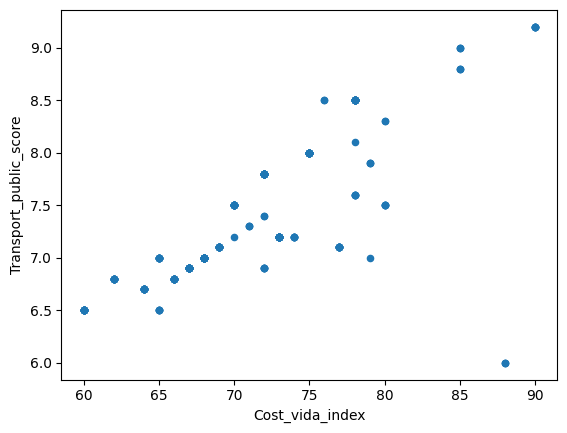

In [133]:
dataset_s8.plot.scatter(
    x='Cost_vida_index',
    y='Transport_public_score'
)

En ambas columnas los datos estan muy agrupados y tienen una correlación entre ambas columnas. Para repartirlos en 3 categorias iguales se utilizarán los quantiles 0.33 y 0.66.

La función que calcula el incremento salarial toma datos de cada usuario (fila) y va sumando los porcentajes al incremento. Al final comprueba que sea inferior o igual al máximo incremento indicado en las politicas salariales.

In [134]:
def calcular_incremento_salarial(fila):
    incremento = 0
    
    # grupo professional
    if pd.notna(fila['Grup Professional']) and fila['Grup Professional'] in politica_salarial['base_increment_by_group']:
        incremento += politica_salarial['base_increment_by_group'][fila['Grup Professional']]

    # nombre de hijos
    if pd.notna(fila['Nombre fills']) and fila['Nombre fills'] > 0:
        incremento += politica_salarial['children_adjustment']['has_children']

    # edad
    if pd.notna(fila['Edat']) and 30 <= fila['Edat'] <= 44:
        incremento += politica_salarial['age_adjustment']['30-44']
    elif pd.notna(fila['Edat']) and 45 <= fila['Edat'] <= 59:
        incremento += politica_salarial['age_adjustment']['45-59']
    elif pd.notna(fila['Edat']) and fila['Edat'] >= 60:
        incremento += politica_salarial['age_adjustment']['60+']

    #coste de vida
    if pd.notna(fila['Cost_vida_index']) and fila['Cost_vida_index'] <= dataset_s8['Cost_vida_index'].quantile(0.33):
        incremento += politica_salarial['cost_of_living_adjustment']['low']
    if pd.notna(fila['Cost_vida_index']) and dataset_s8['Cost_vida_index'].quantile(0.33) < fila['Cost_vida_index'] <= dataset_s8['Cost_vida_index'].quantile(0.66):
        incremento += politica_salarial['cost_of_living_adjustment']['medium']
    if pd.notna(fila['Cost_vida_index']) and dataset_s8['Cost_vida_index'].quantile(0.66) < fila['Cost_vida_index']:
        incremento += politica_salarial['cost_of_living_adjustment']['high']

    # ajuste transporte
    if pd.notna(fila['Transport_public_score']) and fila['Transport_public_score'] <= dataset_s8['Transport_public_score'].quantile(0.33):
        incremento += politica_salarial['transport_adjustment']['low']
    if pd.notna(fila['Transport_public_score']) and dataset_s8['Transport_public_score'].quantile(0.33) < fila['Transport_public_score'] <= dataset_s8['Transport_public_score'].quantile(0.66):
        incremento += politica_salarial['transport_adjustment']['medium']
    if pd.notna(fila['Transport_public_score']) and dataset_s8['Transport_public_score'].quantile(0.66) < fila['Transport_public_score']:
        incremento += politica_salarial['transport_adjustment']['high']

    # max increment
    if incremento > politica_salarial['rules']['max_total_increment_percent']:
        incremento = politica_salarial['rules']['max_total_increment_percent']

    return incremento

In [135]:
dataset_s8['Incremento %'] = dataset_s8.apply(calcular_incremento_salarial, axis=1)

Como una de las condiciones de policita salariales es 800€ de salario mínimo. Una vez se haya aplicado el porcentaje de incremento y no se tenga un salario igual o superior a esa cantidad, el salario será de 800€.

Estas serán las personas que se beneficiarán del salario mínimo.

In [136]:
dataset_s8[dataset_s8['Salari mensual €']<800]

,index,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual €,Grup Professional,Càrrec,...,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat,Grup edat,País,Cost_vida_index,Transport_public_score,Clima_tipus,Incremento %
41,139,Marco,Rossi Ricci,94597104C,Itàlia,Torino,NaN,771.0,Grup A,Analista,...,1983-06-22,True,Analista junior,43.0,36-45,Itàlia,74.0,7.2,Continental,9.5
64,220,Claudia,Sánchez Roca,99482259Y,Espanya,Las Palmas de Gran Canaria,Dona,781.0,Grup A,Analista,...,1981-01-28,True,Analista junior,45.0,36-45,Espanya,62.0,6.8,Subtropical,9.0
77,274,Chiara,Greco,75297400W,Itàlia,Genova,Dona,785.0,Grup A,Responsable de vendes,...,1998-12-12,True,NaN,28.0,25-35,Itàlia,72.0,6.9,Mediterrani,6.5
155,513,Marina,Puig Hernández,78276312M,Espanya,Tarragona,Dona,770.0,Grup A,Analista,...,1971-09-27,True,Analista,55.0,46-55,Espanya,67.0,6.9,Mediterrani,9.0
198,669,Paul,Laurent,39510761M,França,Bordeaux,Dona,746.0,Grup A,Tècnic IT,...,1993-10-11,True,NaN,33.0,25-35,França,73.0,7.2,Oceànic,7.0
200,677,Maja,Nilsen,62978421F,Noruega,Bergen,Home,796.0,Grup A,Analista,...,1978-12-04,True,Analista de dades,48.0,46-55,Noruega,85.0,8.8,Oceànic,8.5
229,760,Oriol,Ferrer,52590001R,Espanya,Zaragoza,Dona,786.0,Grup A,Analista,...,1973-07-15,True,Analista,53.0,46-55,Espanya,68.0,7.0,Continental,7.5
233,776,Pol,Soler Sánchez,34254080R,Espanya,Tarragona,Home,765.0,Grup A,Analista,...,1964-03-30,True,Analista junior,62.0,56 +,Espanya,67.0,6.9,Mediterrani,8.5
268,879,Carlos,Díaz,88598588G,Espanya,Màlaga,Dona,797.0,Grup A,Analista,...,1981-06-16,True,Analista de dades,45.0,36-45,NaN,NaN,NaN,NaN,7.0


Aplico el calculo del salario incrementado

In [137]:
dataset_s8['Salario incrementado'] = round(dataset_s8['Salari mensual €'] + (dataset_s8['Salari mensual €'] * (dataset_s8['Incremento %']/100)),2)

In [138]:
def obtener_salario_minimo(fila):
    
    if fila['Salario incrementado'] < politica_salarial['rules']['min_salary_threshold']:
        fila['Salario incrementado'] = politica_salarial['rules']['min_salary_threshold']

    return fila['Salario incrementado']

In [139]:
dataset_s8['Salario incrementado'] = dataset_s8.apply(obtener_salario_minimo, axis=1)

Aprovecho para corregir los nombres de las nuevas columnas agregadas por ciutat_context y también para borar la columna País 

In [140]:
dataset_s8.columns = dataset_s8.columns.map(corregir_texto)
dataset_s8.drop(['País'], axis=1, inplace=True)
dataset_s8.info()

<class 'pandas.DataFrame'>
RangeIndex: 307 entries, 0 to 306
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   index                       307 non-null    int64         
 1   Nom                         307 non-null    str           
 2   Cognoms                     307 non-null    str           
 3   DNI                         307 non-null    str           
 4   País d'origen               307 non-null    str           
 5   Ciutat                      307 non-null    str           
 6   Gènere                      282 non-null    str           
 7   Salari mensual €            307 non-null    float64       
 8   Grup Professional           307 non-null    str           
 9   Càrrec                      307 non-null    str           
 10  Nombre fills                210 non-null    Int64         
 11  Km anuals                   307 non-null    float64       
 12  Consu

#### Casos incremento salarial no aplicados

Hay trabajadores (132) que no tienen datos en alguna de las 4 columnas que influían para calcular el incremento salarial.

In [141]:
dataset_s8[
    (dataset_s8['Nombre fills'].isna())|
    (dataset_s8['Cost vida index'].isna())|
    (dataset_s8['Transport public score'].isna())|
    (dataset_s8['Grup edat'].isna())
    ]

,index,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual €,Grup Professional,Càrrec,...,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat,Grup edat,Cost vida index,Transport public score,Clima tipus,Incremento %,Salario incrementado
2,9,David,Gómez Vila,36998038E,Espanya,Palma,Dona,2349.0,Grup B,Cap de projecte,...,1971-09-25,True,NaN,55.0,46-55,73.0,7.2,Mediterrani,6.5,2501.68
5,15,Aina,Pérez,31172421Z,Espanya,Las Palmas de Gran Canaria,Home,3672.0,Grup D,Cap de projecte,...,1973-06-10,True,NaN,53.0,46-55,62.0,6.8,Subtropical,10.5,4057.56
6,16,Emilia,Hoffmann,66851377P,Alemanya,Stuttgart,Dona,1003.0,Grup A,Cap de projecte,...,1961-02-21,True,NaN,65.0,56 +,79.0,7.9,Continental,8.0,1083.24
10,21,Nil,Fernández Vidal,69345683K,Espanya,Bilbao,Home,1751.0,Grup B,Analista,...,1978-08-15,True,Analista senior,48.0,46-55,72.0,7.8,Oceànic,6.0,1856.06
11,23,Riccardo,Bianchi,69401199L,Itàlia,Milano,Dona,1121.0,Grup A,Tècnic IT,...,1993-10-11,True,NaN,33.0,25-35,80.0,7.5,Continental,8.0,1210.68
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
293,972,Marta,Vila,69389198K,Espanya,Las Palmas de Gran Canaria,Home,2403.0,Grup C,Administratiu,...,1988-01-13,True,NaN,38.0,36-45,62.0,6.8,Subtropical,3.5,2487.10
298,984,Giulia,Romano,34747698K,Itàlia,Torino,Dona,1316.0,Grup B,Tècnic IT,...,NaT,True,NaN,NaN,NaN,74.0,7.2,Continental,5.5,1388.38
300,989,Ilaria,Ricci Romano,33261698T,Itàlia,Roma,Dona,1225.0,Grup B,Analista,...,1970-04-07,True,Analista de dades,56.0,56 +,78.0,7.6,Mediterrani,7.0,1310.75
303,993,Marc,Hernández,63504799P,Espanya,Zaragoza,Home,3486.0,Grup D,Tècnic IT,...,1990-11-30,True,NaN,36.0,36-45,68.0,7.0,Continental,9.5,3817.17


Pero ningún trabajador al cual no se le ha podido calcular el incremento

In [142]:
dataset_s8[
    (dataset_s8['Nombre fills'].isna())&
    (dataset_s8['Cost vida index'].isna())&
    (dataset_s8['Transport public score'].isna())&
    (dataset_s8['Grup edat'].isna())
    ]

,index,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual €,Grup Professional,Càrrec,...,Data de Naixement,Te cotxe calculat,Categoria càrrec,Edat,Grup edat,Cost vida index,Transport public score,Clima tipus,Incremento %,Salario incrementado


A los 132 trabajadores que no es posible determinar si optan o no a un incremento, es por la falta de información al no indicar si tienen hijos, no han determinado su fecha de nacimiento y/o porque la ciudad en la que residen no tiene información sobre el coste de vida o el transporte.

## Ejercicio 2: Reestructuración de datos

Creo un nuevo dataset reestructurando el dataset del sprint. Cojo de valores identificativos DNI, Ciutat, Gènere y Grup Professional. De columna de valores el salario mensual, tráfico y coste de vida.

In [143]:
dataset_s8_melt = pd.melt(
    frame = dataset_s8,
    id_vars = ["DNI", 'Ciutat', 'Gènere', 'Grup Professional'],
    value_vars= ["Salari mensual €", 'Transport public score', 'Cost vida index'],
    var_name = 'Variables trabajador',
    value_name= 'Valores',
)

In [144]:
dataset_s8_melt.sort_values(by='DNI')

,DNI,Ciutat,Gènere,Grup Professional,Variables trabajador,Valores
690,10443906N,Tarragona,Dona,Grup B,Cost vida index,67.0
383,10443906N,Tarragona,Dona,Grup B,Transport public score,6.9
76,10443906N,Tarragona,Dona,Grup B,Salari mensual €,1632.0
369,10968781V,Tarragona,Dona,Grup A,Transport public score,6.9
62,10968781V,Tarragona,Dona,Grup A,Salari mensual €,935.0
...,...,...,...,...,...,...
13,99853245A,Paris,Dona,Grup B,Salari mensual €,1840.0
12,99853245A,Paris,Dona,Grup B,Salari mensual €,1840.0
319,99853245A,Paris,Dona,Grup B,Transport public score,9.0
320,99853245A,Paris,Dona,Grup B,Transport public score,6.0


Hago la misma operación en ambos datasets:

In [145]:
dataset_s8.groupby(['Gènere'])[['Cost vida index','Salari mensual €','Transport public score']].mean()

,Cost vida index,Salari mensual €,Transport public score
Gènere,,,
Dona,71.358974,1460.842857,7.319231
Home,70.464646,1719.803738,7.312121


<Axes: >

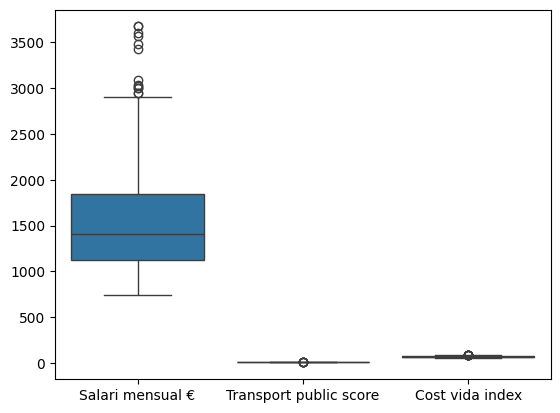

In [146]:
sns.boxplot(
    data=dataset_s8[[ 'Salari mensual €','Transport public score','Cost vida index']]
    )

In [147]:
dataset_s8_melt.groupby(['Gènere', 'Variables trabajador'])['Valores'].mean()

Gènere  Variables trabajador  
Dona    Cost vida index             71.358974
        Salari mensual €          1460.842857
        Transport public score       7.319231
Home    Cost vida index             70.464646
        Salari mensual €          1719.803738
        Transport public score       7.312121
Name: Valores, dtype: float64

<Axes: xlabel='Variables trabajador', ylabel='Valores'>

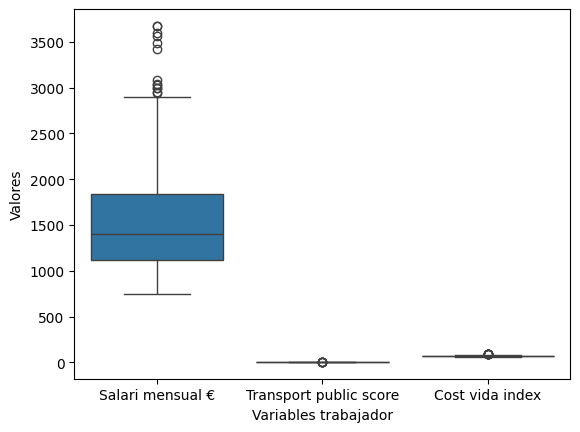

In [148]:
sns.boxplot(
    data=dataset_s8_melt,
    x='Variables trabajador',
    y='Valores'
)

El dataset con melt da la opción de crear un código más corto a cuantas más variables tengas, permite agrupar en una misma columna todos los valores de las variables sin tener que ir operando con distintas columnas (mejor agrupación, comparaciones...).

El formato ancho es mejor para almacenaje de información. Tiene una lectura más estandarizada en formato fila por usuario, pero para agrupaciones y cálculos es compleja.

Este cambio de formato ancho a largo facilita la comparación entre identificadores y cálculo de estadística al trabajar solamente con una columna. 

## Ejercicio 3: Creación de variables derivadas (Feature Engineering)

### Objetivo

Crear al menos 3 nuevas variables derivadas a partir de la información existente, justificar su utilidad y detectar casos límite o incoherencia.

Ejemplos:

- Indice de dependencia familiar: salario mensual / (Nombre hijos + 1)
- Indice de mobilidad: km anuales / temperatura media
- Rátio salarial / coste de vida
- Indicador de dependencia familiar: Salario / Nombre de hijos
- Peso de responsabilidad familiar: Nombre hijos * Edad
- Indicador de etapa vital: 0 sin cargas; 1 etapa activa; 2 alta dependencia

### Mis 3 variables derivadas:

#### Poder adquisitivo:

Calcula la cantidad de bienes y servicios que puedes comprar con el salario dependiendo del coste de vida.

Representa si el salario de los trabajadores es competitivo respecto al nivel de la ciudad en la que residen y posibilita comparar el nivel de bienestar entre diferentes entornos.

- Valor alto -> mayor poder adquisitivo
- Valor bajo -> menor poder adquisitivo

El indicador es sensible a los salarios muy altos en ciudades con costes de vida muy bajos (o viceversa) o en ciudades donde hay poca representación de trabajadores. Estos valores darán índices extremos.

In [149]:
dataset_s8['Poder adquisitivo'] = dataset_s8['Salario incrementado'] / dataset_s8['Cost vida index']

#### Índice de dependencia familiar:

Calcula la dependencia familiar a partir del salario respecto al nombre de hijos. A más hijos, menor.

Representa los recursos disponibles en relación al número de miembros de la familia.

- Valor alto -> menor presión
- Valor bajo -> mayor presión

Los casos a revisar serían las personas con salarios muy bajos o con número de hijos nulo. En esos casos, el resultado del índice saldría vacío o muy diferente.

In [150]:
dataset_s8['Índice de dependencia familiar'] = dataset_s8['Salario incrementado'] / (dataset_s8['Nombre fills']+1)

#### Coste anual estimado de combustible €:

Calculo aproximado del gasto de los trabajadores en combustible si el precio del litro es de 1.6€/Litro (precio orientativo).

Estima el coste de los trabajadores respecto a su kilometraje y la cantidad que destinan de su salario al desplazamiento al lugar de trabajo.

- Valor alto -> mayor gasto energético, económico e impacto ambiental
- Valor bajo -> menor gasto energético, económico e impacto ambiental.

Casos a revisar sería donde el usuario indica un consumo medio anormalmente bajos, muy altos o cerca del 0. También depende del precio del litro indicado, el cual es variable en el tiempo, en el país o distribuidora.

In [151]:
dataset_s8['Coste anual estimado de combustible €'] = ((dataset_s8['Km anuals']/100)*dataset_s8['Consum mitja L 100km'])*1.6

#### Formato largo con las variables derivadas

In [152]:
dataset_indicadores_melt = pd.melt(
    dataset_s8,
    id_vars=['Ciutat',"País d'origen",'Gènere','Grup Professional','Nombre fills'],
    value_vars=['Índice de dependencia familiar','Poder adquisitivo','Coste anual estimado de combustible €'],
    var_name='Índices',
    value_name='Valor índice'
)

In [153]:
dataset_indicadores_melt.groupby(["País d'origen",'Gènere','Índices'])['Valor índice'].mean()

País d'origen  Gènere  Índices                              
Alemanya       Dona    Coste anual estimado de combustible €    13182.549867
                       Poder adquisitivo                           20.438579
                       Índice de dependencia familiar             827.930214
               Home    Coste anual estimado de combustible €           640.0
                       Poder adquisitivo                             22.8375
                       Índice de dependencia familiar                   <NA>
Espanya        Dona    Coste anual estimado de combustible €    13213.319291
                       Poder adquisitivo                            22.79358
                       Índice de dependencia familiar             991.940617
               Home    Coste anual estimado de combustible €    10451.282697
                       Poder adquisitivo                           26.868501
                       Índice de dependencia familiar            1220.071146
França         

## Ejercicio 4: Exportación y síntesis de resultados

### Objetivo:

Consolidar resultados obtenidos después de la preparación, enriquecimiento y creación de variables. Generar salidas estructuradas reutilizables para el análisis o reporting.

Focus:
- Organización de los datos por grupos relevantes.
- Generación de datasets finales coherentes.
- Capacidad de sintetizar información clave.

Aspectos a revisar:
- Qué nivel de agrupación es más adecuado para la exportación de resultados?
- Como separar datos detallados en datos agregados.
- Que información es relevante para un úso posterior (análisis, visualización, reporting...)?

Tareas:
- Utilizar un bucle para exportar 4 ficheros (formato csv o xlsx) para los datos correspondientes a cada grupo profesional.
- Crear y exportar un 5º DataFrame (formato csv o xlsx) que contenga para cada grupo profesional:
    - Número total de trabajdores.
    - Salario medio.
    - Edat media.
- Extra: exportar cada grupo profesional en una pestaña de un mismo excel y una pestaña resumen.

### Exportación

Se ha exportado toda la información del dataset menos las columnas:
- "índex" al no ser de utilidad
- "Salari mensual €" al poder obtenerse a partir de un calculo con "Incremento %" y "Salario incrementado".
- "Data de Naixement". Ya existe grupo de edad y edad.

La información descargada es en formato ancho para facilitar la visualización en un Excel. Para un posterior análisis, al tener gran parte de la información del DataFrame, da la opción de hacer un mayor filtrado sin haber perdido información.

Se genera un archivo independiente para cada grupo y un archivo general con una pestaña para cada grupo y una pestaña de resumen.

In [154]:
def exportar_xlsx(dataset):
    # ruta de exportación
    ruta = './data_grupos/'

    # Creo la ruta si no está creada
    if not os.path.isdir(ruta):
        os.mkdir(ruta)

    # Lista de todas las columnas que quiero para la información de cada grupo
    descarte_columnas = ['index','Salari mensual €','Data de Naixement']
    columnas = [col for col in dataset_s8.columns 
                if col not in descarte_columnas]

    # Creo el dataset con las columnas elegidas
    dataset = dataset[columnas]

    # Defino el dataset resumen
    dataset_resumen = dataset.groupby('Grup Professional').agg(
        Empleados=('DNI','count'),
        Salario_medio=('Salario incrementado','mean'),
        Edat_media=('Edat','mean'))

    with pd.ExcelWriter(f'{ruta}datos_grupos.xlsx', engine='openpyxl') as writer:
    # Bucle de exportar el dataset de cada grupo con toda la información
        for grupo in dataset['Grup Professional'].unique():
            dataset_grupo = dataset[dataset['Grup Professional']==grupo]
            dataset_grupo.to_excel(rf'{ruta}datos_{grupo}.xlsx',index=False)
            dataset_grupo.to_excel(writer, sheet_name=grupo,index=False)
        
    
        dataset_resumen.to_excel(writer, sheet_name='Resumen grupos')

In [155]:
exportar_xlsx(dataset_s8)

# NIVEL 3: Exploración visual y optimización aplicada

Este ejercicio se centra en crear una función que ayude a crear (y exportar) un gráfico automáticamente para cada columna del dataframe.

## Ejercicio 1: Exploración visual del dataset

Importo los dataset. Hago ingo() y sample() para ver que tipo de datos són y un ejemplo de los valores.

In [156]:
iris_dataset = sns.load_dataset('iris')


In [157]:
titanic_dataset = sns.load_dataset('titanic')

In [164]:
penguins_dataset = sns.load_dataset('penguins')

In [158]:
iris_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [159]:
iris_dataset.sample(5)

,sepal_length,sepal_width,petal_length,petal_width,species
127,6.1,3.0,4.9,1.8,virginica
61,5.9,3.0,4.2,1.5,versicolor
88,5.6,3.0,4.1,1.3,versicolor
107,7.3,2.9,6.3,1.8,virginica
7,5.0,3.4,1.5,0.2,setosa


In [165]:
penguins_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


In [160]:
titanic_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [161]:
titanic_dataset.sample(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
151,1,1,female,22.0,1,0,66.6000,S,First,woman,False,C,Southampton,yes,False
551,0,2,male,27.0,0,0,26.0000,S,Second,man,True,NaN,Southampton,no,True
90,0,3,male,29.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
867,0,1,male,31.0,0,0,50.4958,S,First,man,True,A,Southampton,no,True
521,0,3,male,22.0,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True


In [166]:
penguins_dataset.sample(5)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
288,Gentoo,Biscoe,43.5,14.2,220.0,4700.0,Female
243,Gentoo,Biscoe,46.3,15.8,215.0,5050.0,Male
144,Adelie,Dream,37.3,16.8,192.0,3000.0,Female
17,Adelie,Torgersen,42.5,20.7,197.0,4500.0,Male
164,Chinstrap,Dream,47.0,17.3,185.0,3700.0,Female


Ahora comienzo a crear las funciones individualizadas para crear gráficos según tipología de la columna.

In [177]:
def col_float(col, dataset):
    sns.boxplot(data=dataset, x= col)
    return plt.show()

In [197]:
def col_int(col, dataset):
    sns.countplot(data=dataset, x=col)
    return plt.show()

In [217]:
def col_str(col, dataset):
    sns.countplot(data=dataset, x=col)
    return plt.show()

In [218]:
def col_bool(col, dataset):
    sns.countplot(data=dataset, x=col)
    return plt.show()

In [ ]:
def col_cat(dataset):
    pass

In [ ]:
def col_temp(dataset):
    pass

In [215]:
def generar_graficos(dataset):
    sns.set_theme(style='darkgrid',palette='pastel')
    for col in dataset.columns:
        if dataset[col].dtypes == float:
            col_float(col, dataset)
        elif dataset[col].dtypes == int:
            col_int(col, dataset)
        elif dataset[col].dtypes == str:
            col_str(col, dataset)
        elif dataset[col].dtypes == bool:
            col_bool(col, dataset)

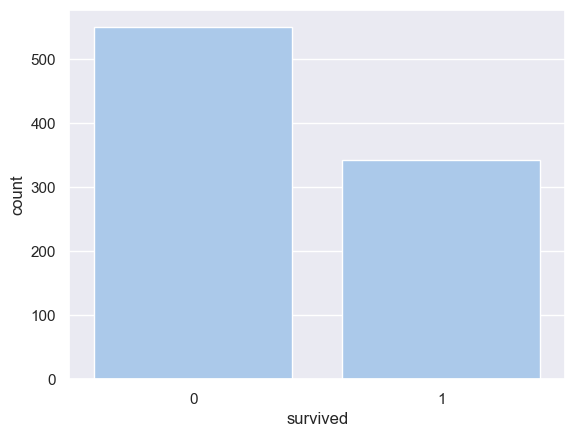

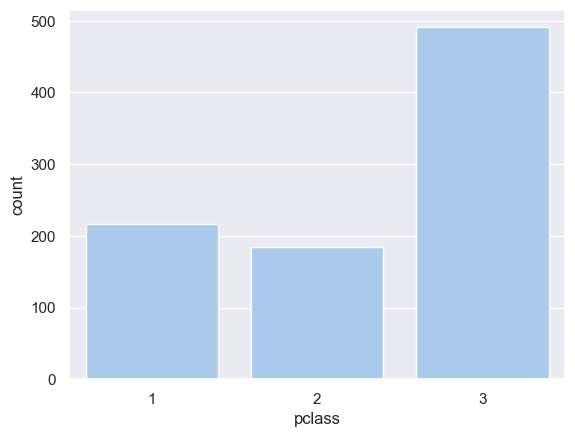

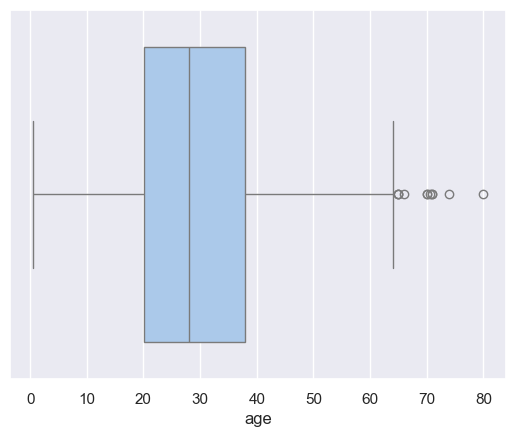

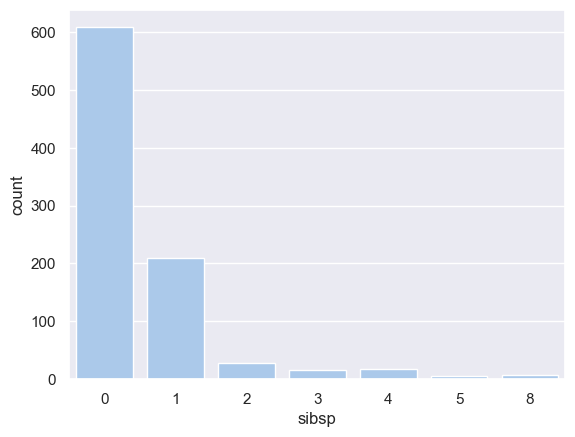

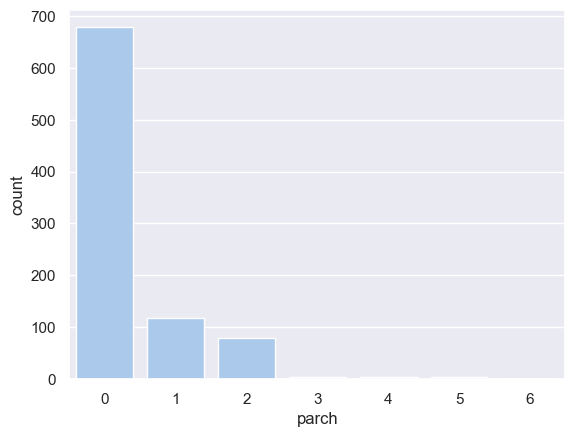

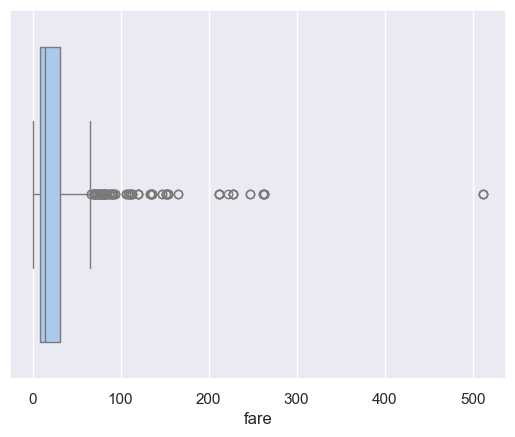

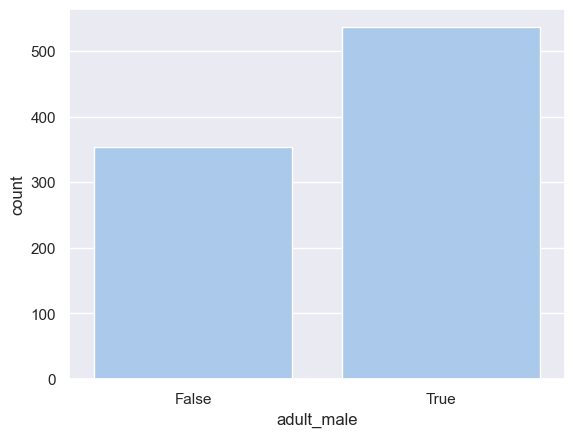

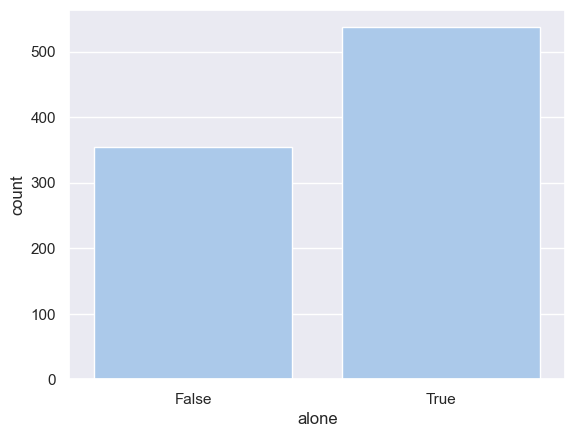

In [219]:
generar_graficos(titanic_dataset)